## 主題關鍵詞檢視與命名

### 模型主題關鍵詞分析

In [ ]:
import pandas as pd
import os
from tabulate import tabulate

def get_enhanced_topics_for_dataset(dataset_name):
    """獲取指定資料集的增強主題

    優先順序: 人工命名 > LLM命名 > 無命名

    Args:
        dataset_name: 資料集名稱 (如 'operation_positive')

    Returns:
        tuple: (enhanced_topics_dict, source_name)
    """
    # 檢查人工命名 (最高優先級)
    manual_var = f'{dataset_name}_enhanced'
    if manual_var in globals() and globals()[manual_var]:
        enhanced_topics = globals()[manual_var]
        return enhanced_topics, "人工命名"

    # 檢查LLM命名
    llm_var = f'{dataset_name}_enhanced_llm'
    if llm_var in globals() and globals()[llm_var]:
        enhanced_topics = globals()[llm_var]
        return enhanced_topics, "LLM命名"

    # 檢查其他可能的命名變數 (向後相容)
    alt_vars = [
        f'{dataset_name}_topics_enhanced',
        f'{dataset_name}_manual_enhanced'
    ]

    for alt_var in alt_vars:
        if alt_var in globals() and globals()[alt_var]:
            enhanced_topics = globals()[alt_var]
            return enhanced_topics, "備用命名"

    return None, "無命名"

def analyze_model_topics(model, model_name, dataset_name=None, enhanced_topics=None, top_n=15):
    """分析單一模型的主題關鍵詞

    Args:
        model: BERTopic模型
        model_name: 模型顯示名稱
        dataset_name: 資料集名稱，用於自動獲取增強主題
        enhanced_topics: 直接提供的增強主題字典（如果有）
        top_n: 輸出前N個主題

    Returns:
        主題分析結果字典
    """
    print(f"\n{'='*60}")
    print(f"分析 {model_name} 模型")
    print(f"{'='*60}")

    # 獲取主題資訊
    topic_info = model.get_topic_info()
    non_outlier_topics = topic_info[topic_info['Topic'] != -1].sort_values("Count", ascending=False)

    # 基本統計
    total_docs = topic_info['Count'].sum()
    outlier_count = topic_info[topic_info['Topic'] == -1]['Count'].values[0] if -1 in topic_info['Topic'].values else 0
    valid_topics = len(non_outlier_topics)
    coverage_rate = (total_docs - outlier_count) / total_docs * 100

    print(f"模型基本統計:")
    print(f"  總文檔數: {total_docs}")
    print(f"  有效主題數: {valid_topics}")
    print(f"  離群文檔: {outlier_count} ({outlier_count/total_docs*100:.1f}%)")
    print(f"  覆蓋率: {coverage_rate:.1f}%")

    # 獲取增強主題
    naming_source = "無命名"
    if enhanced_topics is None and dataset_name:
        enhanced_topics, naming_source = get_enhanced_topics_for_dataset(dataset_name)
    elif enhanced_topics is not None:
        naming_source = "直接提供"

    # 檢查增強主題的狀態
    if enhanced_topics:
        print(f"  增強主題: 已載入 {len(enhanced_topics)} 個命名 ({naming_source})")
    else:
        print(f"  增強主題: 未載入，將使用關鍵詞組合命名")

    # 取前N個主題
    top_topics = non_outlier_topics.head(top_n)

    print(f"\n前 {len(top_topics)} 個最大主題詳細分析:")
    print("-" * 80)

    # 準備CSV數據
    csv_data = []

    for idx, (_, row) in enumerate(top_topics.iterrows(), 1):
        topic_id = row['Topic']
        topic_size = row['Count']
        topic_percentage = topic_size / total_docs * 100

        # 獲取主題關鍵詞（前10個）
        topic_keywords = model.get_topic(topic_id)[:10]

        # 主題名稱
        if enhanced_topics and topic_id in enhanced_topics:
            topic_name = enhanced_topics[topic_id]['name']
            name_source = naming_source
        else:
            # 使用前2個關鍵詞作為主題名稱
            top_words = [word for word, _ in topic_keywords[:2]]
            topic_name = "-".join(top_words)
            name_source = "關鍵詞組合"

        print(f"\n【主題 {idx}】主題ID: {topic_id}")
        print(f"主題名稱: {topic_name} ({name_source})")
        print(f"文檔數量: {topic_size} ({topic_percentage:.1f}%)")
        print(f"關鍵詞:")

        # 顯示關鍵詞
        for i, (word, weight) in enumerate(topic_keywords, 1):
            print(f"  {i:2d}. {word} ({weight:.4f})")

        # 準備CSV行數據
        csv_row = {
            '排名': idx,
            '主題ID': topic_id,
            '主題名稱': topic_name,
            '名稱來源': name_source,
            '文檔數': topic_size,
            '佔比(%)': f"{topic_percentage:.2f}%",
            '模型名稱': model_name,
            '資料集': dataset_name if dataset_name else "未指定"
        }

        # 添加關鍵詞列
        for i, (word, weight) in enumerate(topic_keywords, 1):
            csv_row[f'關鍵詞{i}'] = word
            csv_row[f'權重{i}'] = f"{weight:.4f}"

        csv_data.append(csv_row)

    return {
        'model_name': model_name,
        'dataset_name': dataset_name,
        'total_docs': total_docs,
        'valid_topics': valid_topics,
        'outlier_count': outlier_count,
        'coverage_rate': coverage_rate,
        'enhanced_count': len(enhanced_topics) if enhanced_topics else 0,
        'naming_source': naming_source,
        'csv_data': csv_data
    }

def verify_models_exist():
    """驗證所有預期的模型是否存在"""
    print("驗證模型存在性...")
    print("-" * 40)

    expected_models = [
        ('operation_positive_model', 'operation_positive', '營運活動正面情緒'),
        ('operation_negative_model', 'operation_negative', '營運活動負面情緒'),
        ('ip_positive_model', 'ip_positive', 'IP聯動正面情緒'),
        ('ip_negative_model', 'ip_negative', 'IP聯動負面情緒'),
        ('balance_update_model', 'balance_update', '平衡性版本更新'),
    ]

    available_models = []
    missing_models = []

    for model_var, dataset_name, display_name in expected_models:
        if model_var in globals() and globals()[model_var] is not None:
            available_models.append((model_var, dataset_name, display_name))
            print(f"  找到: {display_name}")
        else:
            missing_models.append((model_var, dataset_name, display_name))
            print(f"  缺失: {display_name}")

    print(f"\n可用模型: {len(available_models)}/{len(expected_models)}")

    if missing_models:
        print("缺失的模型:")
        for model_var, _, display_name in missing_models:
            print(f"  - {display_name} ({model_var})")
        print("\n請先執行模型載入步驟 (9.0) 或模型訓練步驟 (8.1-8.5)")

    return available_models

def analyze_all_models():
    """分析所有已訓練的模型"""
    print("開始分析所有模型的主題關鍵詞...")
    print("=" * 80)

    # 首先驗證模型存在性
    available_models = verify_models_exist()

    if not available_models:
        print("錯誤: 沒有找到任何可用的模型")
        return []

    all_results = []
    all_csv_data = []

    for model_var, dataset_name, display_name in available_models:
        print(f"\n{'='*50}")
        print(f"處理模型: {display_name}")
        print('='*50)

        try:
            model = globals()[model_var]
            print(f"模型已載入: {model_var}")

            # 分析模型 - 傳入dataset_name以自動獲取增強主題
            result = analyze_model_topics(
                model=model,
                model_name=display_name,
                dataset_name=dataset_name,
                top_n=15
            )
            all_results.append(result)

            # 合併CSV數據
            all_csv_data.extend(result['csv_data'])

        except Exception as e:
            print(f"分析 {display_name} 時發生錯誤: {str(e)}")
            continue

    # 生成總結報告
    if all_results:
        print(f"\n\n{'='*80}")
        print("所有模型總結報告")
        print("="*80)

        summary_data = []
        for result in all_results:
            summary_data.append([
                result['model_name'],
                result['total_docs'],
                result['valid_topics'],
                f"{result['outlier_count']} ({result['outlier_count']/result['total_docs']*100:.1f}%)",
                f"{result['coverage_rate']:.1f}%",
                f"{result['enhanced_count']}個",
                result['naming_source']
            ])

        headers = ['模型名稱', '總文檔數', '有效主題數', '離群文檔', '覆蓋率', '已命名主題', '命名來源']
        print(tabulate(summary_data, headers=headers, tablefmt="grid"))

        # 儲存詳細CSV報告
        if all_csv_data:
            save_analysis_results(all_results, all_csv_data)

    return all_results

def save_analysis_results(all_results, all_csv_data):
    """儲存分析結果到CSV檔案"""
    try:
        # 檢查PIPELINE_CONFIG是否存在
        if 'PIPELINE_CONFIG' not in globals():
            print("警告: PIPELINE_CONFIG 未定義，無法儲存結果")
            return

        results_dir = os.path.join(PIPELINE_CONFIG['data']['base_path'], PIPELINE_CONFIG['output']['results_dir'])
        os.makedirs(results_dir, exist_ok=True)

        # 儲存合併的分析結果
        csv_path = os.path.join(results_dir, 'all_models_topics_keywords_analysis.csv')
        df = pd.DataFrame(all_csv_data)
        df.to_csv(csv_path, index=False, encoding='utf-8-sig')
        print(f"\n詳細主題關鍵詞分析已儲存至: {csv_path}")

        # 為每個模型單獨儲存CSV
        for result in all_results:
            if result['csv_data']:
                model_csv_data = result['csv_data']
                safe_model_name = result['model_name'].replace('/', '_').replace(' ', '_').replace('-', '_')
                model_csv_path = os.path.join(results_dir, f"{safe_model_name}_topics_keywords.csv")
                model_df = pd.DataFrame(model_csv_data)
                model_df.to_csv(model_csv_path, index=False, encoding='utf-8-sig')
                print(f"{result['model_name']} 主題分析已儲存至: {os.path.basename(model_csv_path)}")

    except Exception as e:
        print(f"儲存分析結果時發生錯誤: {str(e)}")

def generate_keywords_summary():
    """生成關鍵詞統計摘要"""
    print(f"\n{'='*80}")
    print("生成跨模型關鍵詞統計摘要...")
    print("="*80)

    # 驗證模型存在性
    available_models = verify_models_exist()
    if not available_models:
        print("錯誤: 沒有找到任何可用的模型")
        return {}

    keyword_frequency = {}

    for model_var, dataset_name, display_name in available_models:
        try:
            model = globals()[model_var]
            topic_info = model.get_topic_info()

            # 獲取前10個主題的所有關鍵詞
            top_topics = topic_info[topic_info['Topic'] != -1].sort_values("Count", ascending=False)['Topic'][:10]

            print(f"\n{display_name} 前10個主題的高頻關鍵詞:")
            model_keywords = []

            for topic_id in top_topics:
                keywords = model.get_topic(topic_id)[:5]  # 每個主題取前5個關鍵詞
                for word, weight in keywords:
                    model_keywords.append(word)
                    if word not in keyword_frequency:
                        keyword_frequency[word] = []
                    keyword_frequency[word].append((display_name, weight))

            # 顯示該模型的獨特關鍵詞
            from collections import Counter
            word_counts = Counter(model_keywords)
            print("  高頻詞:", ', '.join([f"{word}({count})" for word, count in word_counts.most_common(15)]))

        except Exception as e:
            print(f"分析 {display_name} 關鍵詞時發生錯誤: {str(e)}")
            continue

    # 找出跨模型的共同關鍵詞
    print(f"\n跨模型共同關鍵詞分析:")
    cross_model_keywords = {word: models for word, models in keyword_frequency.items() if len(models) >= 2}

    if cross_model_keywords:
        print("出現在多個模型中的關鍵詞:")
        for word, models in sorted(cross_model_keywords.items(), key=lambda x: len(x[1]), reverse=True)[:20]:
            model_list = [model_name for model_name, _ in models]
            print(f"  {word}: {', '.join(model_list)} (出現在{len(models)}個模型)")
    else:
        print("未找到跨模型的共同關鍵詞")

    return keyword_frequency

def debug_enhanced_topics():
    """調試函數：檢查所有增強主題變數"""
    print("調試：檢查所有增強主題變數")
    print("="*50)

    datasets = ['operation_positive', 'operation_negative', 'ip_positive', 'ip_negative', 'balance_update']

    for dataset in datasets:
        print(f"\n資料集: {dataset}")

        # 檢查各種可能的變數名稱
        possible_vars = [
            f'{dataset}_enhanced',
            f'{dataset}_enhanced_llm',
            f'{dataset}_topics_enhanced',
            f'{dataset}_manual_enhanced'
        ]

        found_any = False
        for var_name in possible_vars:
            if var_name in globals():
                var_value = globals()[var_name]
                if var_value:
                    print(f"  找到: {var_name} = {len(var_value)} 個主題")
                    # 顯示前3個主題名稱作為樣本
                    sample_topics = list(var_value.items())[:3]
                    for topic_id, topic_data in sample_topics:
                        topic_name = topic_data.get('name', '無名稱')
                        print(f"    主題{topic_id}: {topic_name}")
                    found_any = True
                else:
                    print(f"  空值: {var_name} = None 或空")

        if not found_any:
            print(f"  未找到任何增強主題變數")

def run_complete_analysis():
    """執行完整的主題關鍵詞分析流程"""
    print("="*80)
    print("開始進行 9.1 模型主題關鍵詞輸出分析")
    print("="*80)

    # 先調試檢查變數狀態
    debug_enhanced_topics()

    # 分析所有模型
    analysis_results = analyze_all_models()

    if analysis_results:
        # 生成關鍵詞統計摘要
        keyword_stats = generate_keywords_summary()

        print(f"\n{'='*80}")
        print("9.1 模型主題關鍵詞分析完成")
        print("="*80)
        print(f"已分析 {len(analysis_results)} 個模型")
        print(f"詳細結果已儲存至 results 目錄")
        print(f"包含主題關鍵詞、權重、文檔數量等完整資訊")

        return analysis_results, keyword_stats
    else:
        print(f"\n{'='*80}")
        print("9.1 模型主題關鍵詞分析失敗")
        print("="*80)
        print("請確保：")
        print("1. 已執行模型載入步驟 (9.0)")
        print("2. 或已執行模型訓練步驟 (8.1-8.5)")
        print("3. 全域變數 PIPELINE_CONFIG 已定義")

        return [], {}

# 執行完整分析
if __name__ == "__main__":
    analysis_results, keyword_stats = run_complete_analysis()

開始進行 9.1 模型主題關鍵詞輸出分析
調試：檢查所有增強主題變數

資料集: operation_positive
  找到: operation_positive_enhanced = 11 個主題
    主題0: 悟空神操作讚美
    主題1: 官方活動讚美
    主題2: 可愛造型期待

資料集: operation_negative
  找到: operation_negative_enhanced = 14 個主題
    主題0: 造型外觀不滿
    主題1: 遊戲公司商業抱怨
    主題2: 語音質量不滿

資料集: ip_positive
  找到: ip_positive_enhanced = 24 個主題
    主題0: 皇帝得獎祝賀
    主題1: 主播戰神讚美
    主題2: 主播黃金戰神讚美

資料集: ip_negative
  找到: ip_negative_enhanced = 19 個主題
    主題0: 虎杖抽獎結果討論
    主題1: 購買經濟負擔
    主題2: 虎杖抽獎失望

資料集: balance_update
  找到: balance_update_enhanced = 34 個主題
    主題0: 黑貓無敵主播討論
    主題1: 黃金戰神外觀討論
    主題2: 技能削弱討論
開始分析所有模型的主題關鍵詞...
驗證模型存在性...
----------------------------------------
  找到: 營運活動正面情緒
  找到: 營運活動負面情緒
  找到: IP聯動正面情緒
  找到: IP聯動負面情緒
  找到: 平衡性版本更新

可用模型: 5/5

處理模型: 營運活動正面情緒
模型已載入: operation_positive_model

分析 營運活動正面情緒 模型
模型基本統計:
  總文檔數: 918
  有效主題數: 11
  離群文檔: 323 (35.2%)
  覆蓋率: 64.8%
  增強主題: 已載入 11 個命名 (人工命名)

前 11 個最大主題詳細分析:
--------------------------------------------------------------------------------

【

### LLM 主題命名

In [ ]:

import openai
from openai import OpenAI
import time

def check_llm_prerequisites():
    """檢查LLM命名的前置條件"""
    print("檢查LLM命名前置條件...")
    print("=" * 40)

    prerequisites_status = []
    all_ok = True

    # 檢查PIPELINE_CONFIG
    if 'PIPELINE_CONFIG' in globals():
        prerequisites_status.append(("PIPELINE_CONFIG", "存在"))
    else:
        prerequisites_status.append(("PIPELINE_CONFIG", "缺失"))
        all_ok = False

    # 檢查API Key
    if 'PIPELINE_CONFIG' in globals():
        api_key = PIPELINE_CONFIG.get('llm', {}).get('api_key')
        if api_key:
            api_key_display = f"已設定 ({api_key[:8]}...)"
            prerequisites_status.append(("OpenAI API Key", api_key_display))
        else:
            prerequisites_status.append(("OpenAI API Key", "未設定"))
            all_ok = False

    # 檢查enhancer
    if 'enhancer' in globals():
        enhancer = globals()['enhancer']
        if hasattr(enhancer, 'client') and enhancer.client is not None:
            prerequisites_status.append(("LLM Enhancer", "正常"))
        else:
            prerequisites_status.append(("LLM Enhancer", "客戶端未初始化"))
            all_ok = False
    else:
        prerequisites_status.append(("LLM Enhancer", "不存在"))
        all_ok = False

    # 檢查模型
    expected_models = ['operation_positive_model', 'operation_negative_model',
                      'ip_positive_model', 'ip_negative_model', 'balance_update_model']
    available_models = sum(1 for model_var in expected_models if model_var in globals())
    prerequisites_status.append(("可用模型", f"{available_models}/{len(expected_models)}個"))

    if available_models == 0:
        all_ok = False

    # 打印狀態
    for item, status in prerequisites_status:
        print(f"  {item}: {status}")

    return all_ok

def load_saved_models_for_llm():
    """為LLM命名載入已儲存的模型"""
    print("\n載入已儲存的模型...")
    print("=" * 40)

    if 'PIPELINE_CONFIG' not in globals():
        print("錯誤: PIPELINE_CONFIG 未定義")
        return {}

    models_dir = os.path.join(PIPELINE_CONFIG['data']['base_path'], PIPELINE_CONFIG['output']['models_dir'])

    # 模型檔案對應
    model_files = {
        'operation_positive': 'operation_positive_model.pkl',
        'operation_negative': 'operation_negative_model.pkl',
        'ip_positive': 'ip_positive_model.pkl',
        'ip_negative': 'ip_negative_model.pkl',
        'balance_update': 'balance_update_model.pkl'
    }

    loaded_models = {}

    for dataset_name, filename in model_files.items():
        model_path = os.path.join(models_dir, filename)
        model_var = f'{dataset_name}_model'

        # 檢查檔案是否存在
        if os.path.exists(model_path):
            try:
                # 載入模型
                from bertopic import BERTopic
                model = BERTopic.load(model_path)

                # 確保有嵌入模型
                if not hasattr(model, 'embedding_model') or model.embedding_model is None:
                    if 'analyzer' in globals() and hasattr(globals()['analyzer'], 'embedding_model'):
                        model.embedding_model = globals()['analyzer'].embedding_model
                        print(f"  {dataset_name}: 已重新設定嵌入模型")

                # 儲存到全域變數 - 關鍵修復點
                globals()[model_var] = model
                loaded_models[dataset_name] = model

                print(f"已載入 {dataset_name}: {filename}")

            except Exception as e:
                print(f"載入 {dataset_name} 失敗: {str(e)}")
        else:
            print(f"找不到 {dataset_name}: {filename}")

    print(f"\n成功載入 {len(loaded_models)} 個模型")
    return loaded_models

def enhance_single_model_topics(model, dataset_name, enhancer):
    """為單一模型進行主題命名"""
    print(f"\n命名 {dataset_name} 主題...")
    print("-" * 30)

    try:
        # 獲取模型基本資訊
        topic_info = model.get_topic_info()
        non_outlier_topics = topic_info[topic_info['Topic'] != -1]

        print(f"  模型有 {len(non_outlier_topics)} 個有效主題")

        # 進行主題命名
        enhanced = enhancer.enhance_model_topics(model, dataset_name)

        if enhanced:
            print(f"  成功命名 {len(enhanced)} 個主題")
            return enhanced
        else:
            print(f"  命名失敗，返回空結果")
            return {}

    except Exception as e:
        print(f"  命名過程中發生錯誤: {str(e)}")
        return {}

def enhance_all_topics():
    """為所有已訓練的模型進行主題命名"""

    print("開始進行主題命名...")
    print("=" * 50)

    # 檢查前置條件
    if not check_llm_prerequisites():
        print("\n錯誤: 前置條件檢查失敗")
        print("請確保：")
        print("1. PIPELINE_CONFIG 已定義")
        print("2. OpenAI API Key 已設定")
        print("3. enhancer 已初始化")
        print("4. 至少有一個模型可用")
        return None

    # 載入模型（如果需要）
    print("\n檢查並載入模型...")
    model_vars = {
        'operation_positive': 'operation_positive_model',
        'operation_negative': 'operation_negative_model',
        'ip_positive': 'ip_positive_model',
        'ip_negative': 'ip_negative_model',
        'balance_update': 'balance_update_model'
    }

    # 檢查哪些模型需要載入
    missing_models = []
    for dataset_name, model_var in model_vars.items():
        if model_var not in globals():
            missing_models.append(dataset_name)

    if missing_models:
        print(f"需要載入模型: {', '.join(missing_models)}")
        loaded_models = load_saved_models_for_llm()
    else:
        print("所有模型已在記憶體中")

    enhanced_results = {}
    success_count = 0
    total_count = 0

    # 獲取enhancer
    enhancer = globals()['enhancer']

    # 處理每個模型
    for dataset_name, model_var in model_vars.items():
        total_count += 1

        if model_var in globals():
            model = globals()[model_var]

            # 進行主題命名
            enhanced = enhance_single_model_topics(model, dataset_name, enhancer)

            if enhanced:
                enhanced_results[dataset_name] = enhanced
                success_count += 1

                # 儲存增強結果到全域變數 - 關鍵修復點
                # 使用一致的命名規則
                globals()[f'{dataset_name}_enhanced'] = enhanced  # 主要變數
                globals()[f'{dataset_name}_enhanced_llm'] = enhanced  # LLM專用備份

                print(f"  命名結果已儲存至:")
                print(f"    - {dataset_name}_enhanced")
                print(f"    - {dataset_name}_enhanced_llm")
            else:
                print(f"  {dataset_name} 命名失敗")
        else:
            print(f"模型 {model_var} 未找到，跳過")

    # 總結報告
    print(f"\n{'='*50}")
    print("LLM主題命名完成")
    print("="*50)
    print(f"處理模型: {success_count}/{total_count}")

    if enhanced_results:
        print("\n成功命名的模型:")
        for dataset_name, enhanced in enhanced_results.items():
            dataset_desc = PIPELINE_CONFIG['data']['datasets'][dataset_name]['description']
            print(f"  {dataset_desc}: {len(enhanced)} 個主題")

        # 驗證保存結果
        print("\n驗證保存結果:")
        for dataset_name in enhanced_results.keys():
            main_var = f'{dataset_name}_enhanced'
            llm_var = f'{dataset_name}_enhanced_llm'

            main_ok = main_var in globals() and globals()[main_var]
            llm_ok = llm_var in globals() and globals()[llm_var]

            if main_ok and llm_ok:
                print(f"  {dataset_name}: 保存成功")
            else:
                print(f"  {dataset_name}: 保存失敗 (main:{main_ok}, llm:{llm_ok})")
    else:
        print("\n沒有成功命名任何模型")
        print("可能的原因:")
        print("- API Key 無效")
        print("- 網路連接問題")
        print("- 模型資料問題")
        print("- enhancer 配置問題")

    return enhanced_results

def verify_llm_naming_results():
    """驗證LLM命名結果"""
    print("\n驗證LLM命名結果...")
    print("=" * 40)

    datasets = ['operation_positive', 'operation_negative', 'ip_positive', 'ip_negative', 'balance_update']

    verification_results = []

    for dataset in datasets:
        main_var = f'{dataset}_enhanced'
        llm_var = f'{dataset}_enhanced_llm'

        main_exists = main_var in globals() and globals()[main_var]
        llm_exists = llm_var in globals() and globals()[llm_var]

        if main_exists:
            count = len(globals()[main_var])
            status = f"成功 ({count}個主題)"

            # 檢查內容一致性
            if llm_exists:
                if globals()[main_var] == globals()[llm_var]:
                    consistency = "一致"
                else:
                    consistency = "不一致"
            else:
                consistency = "LLM備份缺失"
        else:
            status = "失敗"
            count = 0
            consistency = "無資料"

        verification_results.append([
            PIPELINE_CONFIG['data']['datasets'][dataset]['description'] if 'PIPELINE_CONFIG' in globals() else dataset,
            status,
            consistency
        ])

    from tabulate import tabulate
    headers = ['資料集', '命名狀態', '資料一致性']
    print(tabulate(verification_results, headers=headers, tablefmt="grid"))

def show_llm_naming_samples():
    """顯示LLM命名結果樣本"""
    print("\n顯示LLM命名結果樣本...")
    print("=" * 50)

    datasets = ['operation_positive', 'operation_negative', 'ip_positive', 'ip_negative', 'balance_update']

    for dataset in datasets:
        enhanced_var = f'{dataset}_enhanced'

        if enhanced_var in globals() and globals()[enhanced_var]:
            enhanced_topics = globals()[enhanced_var]
            dataset_desc = PIPELINE_CONFIG['data']['datasets'][dataset]['description'] if 'PIPELINE_CONFIG' in globals() else dataset

            print(f"\n{dataset_desc} - 前3個主題命名樣本:")

            # 取前3個主題作為樣本
            sample_topics = list(enhanced_topics.items())[:3]
            for topic_id, topic_data in sample_topics:
                topic_name = topic_data.get('name', '無名稱')
                keywords = topic_data.get('keywords', [])
                keywords_str = ', '.join(keywords[:5]) if keywords else '無關鍵詞'

                print(f"  主題{topic_id}: {topic_name}")
                print(f"    關鍵詞: {keywords_str}")

def run_llm_naming_workflow():
    """執行完整的LLM命名工作流程"""
    print("="*80)
    print("開始進行 9.2 LLM主題命名 - 完全修復版")
    print("="*80)

    try:
        # 執行主題命名
        enhanced_results = enhance_all_topics()

        if enhanced_results:
            # 驗證結果
            verify_llm_naming_results()

            # 顯示樣本
            show_llm_naming_samples()

            print(f"\n{'='*80}")
            print("9.2 LLM主題命名成功完成")
            print("="*80)

            return enhanced_results
        else:
            print(f"\n{'='*80}")
            print("9.2 LLM主題命名失敗")
            print("="*80)
            print("請檢查:")
            print("1. OpenAI API Key 是否正確設定")
            print("2. 網路連接是否正常")
            print("3. 模型是否已正確載入")
            print("4. enhancer 是否已初始化")

            return None

    except Exception as e:
        print(f"\n{'='*80}")
        print("9.2 LLM主題命名過程中發生錯誤")
        print("="*80)
        print(f"錯誤訊息: {str(e)}")
        print("\n請檢查:")
        print("1. 所有前置條件是否滿足")
        print("2. API配額是否充足")
        print("3. 模型資料是否完整")

        return None

# 快捷函數
def quick_llm_naming():
    """快速執行LLM命名"""
    return run_llm_naming_workflow()

def check_naming_status():
    """檢查當前命名狀態"""
    verify_llm_naming_results()
    show_llm_naming_samples()

# 執行LLM命名工作流程
if __name__ == "__main__":
    enhanced_topics = run_llm_naming_workflow()

開始進行 9.2 LLM主題命名 - 完全修復版
開始進行主題命名...
檢查LLM命名前置條件...
  PIPELINE_CONFIG: 存在
  OpenAI API Key: 已設定 (sk-proj-...)
  LLM Enhancer: 正常
  可用模型: 5/5個

檢查並載入模型...
所有模型已在記憶體中

命名 operation_positive 主題...
------------------------------
  模型有 11 個有效主題
Enhancing topics for 營運活動正面情緒...
Topic 0: 悟空神操作讚美
Topic 1: 官方活動讚美
Topic 2: 可愛造型期待
Topic 3: 直購造型需求
Topic 4: 特效表現讚美
Topic 5: 免費活動期待
Topic 6: 遊戲趣味與可愛角色評價
Topic 7: 語音配音讚賞
Topic 8: 活動獎勵期待
Topic 9: 傳說對決週年期待
Topic 10: 牛牛復刻期待
  成功命名 11 個主題
  命名結果已儲存至:
    - operation_positive_enhanced
    - operation_positive_enhanced_llm

命名 operation_negative 主題...
------------------------------
  模型有 14 個有效主題
Enhancing topics for 營運活動負面情緒...
Topic 0: 造型外觀不滿
Topic 1: 遊戲公司商業抱怨
Topic 2: 語音質量不滿
Topic 3: 造型價格抱怨
Topic 4: 遊戲內溝通無力感
Topic 5: 配對機制改變不滿
Topic 6: 免費獲得需求
Topic 7: 造型特效不滿
Topic 8: 過去活動失望與未來擔憂
Topic 9: 寶箱與聖典造型不滿
Topic 10: 越南服獲取不滿
Topic 11: 盤子抽獎不滿
Topic 12: 抽獎價格不滿
Topic 13: 造型唯一不滿
  成功命名 14 個主題
  命名結果已儲存至:
    - operation_negative_enhanced
    - operation_negative_enhanced

### 主題人工命名

In [ ]:
import pandas as pd
import os
from tabulate import tabulate
import json

class ManualTopicNamer:
    """人工主題命名器"""

    def __init__(self, config):
        self.config = config
        self.manual_naming_history = {}
        self.results_dir = os.path.join(config['data']['base_path'], config['output']['results_dir'])
        os.makedirs(self.results_dir, exist_ok=True)

    def get_current_enhanced_topics(self, dataset_name):
        """獲取當前的增強主題（優先人工命名）"""
        # 優先順序: 人工命名 > LLM命名 > 無
        manual_var = f'{dataset_name}_enhanced'
        llm_var = f'{dataset_name}_enhanced_llm'

        if manual_var in globals() and globals()[manual_var]:
            enhanced_topics = globals()[manual_var]
            source = "人工命名"
        elif llm_var in globals() and globals()[llm_var]:
            enhanced_topics = globals()[llm_var]
            source = "LLM命名"
        else:
            enhanced_topics = None
            source = "無命名"

        return enhanced_topics, source

    def display_current_topics(self, model, dataset_name, enhanced_topics=None, show_docs=True):
        """顯示5個主題的詳細資訊供人工檢視"""
        print(f"\n{'='*80}")
        print(f"主題詳細資訊 - {dataset_name} (每次顯示5個主題)")
        print(f"{'='*80}")

        topic_info = model.get_topic_info()
        non_outlier_topics = topic_info[topic_info['Topic'] != -1].sort_values("Count", ascending=False)

        # 只顯示前5個主題
        top_5_topics = non_outlier_topics.head(5)

        # 如果沒有提供enhanced_topics，嘗試自動獲取
        if enhanced_topics is None:
            enhanced_topics, source = self.get_current_enhanced_topics(dataset_name)
            if enhanced_topics:
                print(f"已載入增強主題: {source} ({len(enhanced_topics)}個)")
            else:
                print(f"未找到增強主題")

        # 獲取所有文檔和主題分配（如果需要顯示相關文檔）
        if show_docs and hasattr(model, 'topics_'):
            # 載入對應的文本資料
            try:
                # 將顯示名稱轉換為資料集key
                dataset_key = self._convert_display_name_to_key(dataset_name)
                if 'processor' in globals():
                    texts = globals()['processor'].get_texts(dataset_key)
                    topics_list = model.topics_
                else:
                    texts = None
                    topics_list = None
            except Exception as e:
                print(f"載入文本資料失敗: {str(e)}")
                texts = None
                topics_list = None
        else:
            texts = None
            topics_list = None

        for idx, (_, row) in enumerate(top_5_topics.iterrows(), 1):
            topic_id = row['Topic']
            topic_size = row['Count']
            topic_percentage = topic_size / topic_info['Count'].sum() * 100

            print(f"\n【主題 {idx}】")
            print(f"主題ID: {topic_id}")
            print(f"文檔數: {topic_size} ({topic_percentage:.1f}%)")

            # 獲取當前名稱
            if enhanced_topics and topic_id in enhanced_topics:
                current_name = enhanced_topics[topic_id]['name']
                name_source = "已命名"
            else:
                topic_keywords = model.get_topic(topic_id)[:2]
                current_name = "-".join([word for word, _ in topic_keywords])
                name_source = "待命名"

            print(f"當前名稱: {current_name} ({name_source})")

            # 獲取前5個關鍵詞
            topic_keywords = model.get_topic(topic_id)[:5]
            print(f"關鍵詞:")
            for i, (word, weight) in enumerate(topic_keywords, 1):
                print(f"  {i}. {word} (權重: {weight:.4f})")

            # 顯示最相關的2個文檔
            if texts and topics_list and len(texts) == len(topics_list):
                topic_docs = []
                for doc_idx, doc_topic in enumerate(topics_list):
                    if doc_topic == topic_id:
                        topic_docs.append((doc_idx, texts[doc_idx]))

                if len(topic_docs) >= 2:
                    print(f"相關文檔範例:")
                    for doc_num, (doc_idx, doc_text) in enumerate(topic_docs[:2], 1):
                        # 限制文檔長度以便顯示
                        display_text = doc_text[:100] + "..." if len(doc_text) > 100 else doc_text
                        print(f"  文檔{doc_num}: {display_text}")
                elif len(topic_docs) == 1:
                    display_text = topic_docs[0][1][:100] + "..." if len(topic_docs[0][1]) > 100 else topic_docs[0][1]
                    print(f"相關文檔範例:")
                    print(f"  文檔1: {display_text}")
                else:
                    print(f"相關文檔: 無法找到相關文檔")

            print("-" * 60)

        return top_5_topics

    def _convert_display_name_to_key(self, display_name):
        """將顯示名稱轉換為資料集key"""
        mapping = {
            '營運活動正面情緒': 'operation_positive',
            '營運活動負面情緒': 'operation_negative',
            'IP聯動正面情緒': 'ip_positive',
            'IP聯動負面情緒': 'ip_negative',
            '平衡性版本更新': 'balance_update'
        }
        return mapping.get(display_name, display_name)

    def manual_rename_single(self, model, dataset_name, topic_id, new_name, enhanced_topics=None):
        """手動重命名單個主題"""
        topic_info = model.get_topic_info()

        if topic_id not in topic_info['Topic'].values:
            print(f"錯誤: 主題ID {topic_id} 不存在")
            return False

        # 如果沒有提供enhanced_topics，獲取當前的
        if enhanced_topics is None:
            enhanced_topics, _ = self.get_current_enhanced_topics(dataset_name)
            if enhanced_topics is None:
                enhanced_topics = {}

        # 獲取原始名稱
        if enhanced_topics and topic_id in enhanced_topics:
            old_name = enhanced_topics[topic_id]['name']
        else:
            topic_keywords = model.get_topic(topic_id)[:2]
            old_name = "-".join([word for word, _ in topic_keywords])

        # 保留原有的關鍵詞資訊
        if topic_id in enhanced_topics:
            enhanced_topics[topic_id]['name'] = new_name
        else:
            topic_keywords = model.get_topic(topic_id)[:8]
            enhanced_topics[topic_id] = {
                'name': new_name,
                'keywords': [word for word, _ in topic_keywords],
                'original_keywords': [f"{word}({weight:.3f})" for word, weight in topic_keywords[:5]]
            }

        # 記錄命名歷史
        if dataset_name not in self.manual_naming_history:
            self.manual_naming_history[dataset_name] = []

        self.manual_naming_history[dataset_name].append({
            'topic_id': topic_id,
            'old_name': old_name,
            'new_name': new_name,
            'timestamp': pd.Timestamp.now().isoformat()
        })

        print(f"完成: 主題 {topic_id} 已重命名")
        print(f"   舊名稱: {old_name}")
        print(f"   新名稱: {new_name}")

        return enhanced_topics

    def batch_rename_interface(self, model, dataset_name, enhanced_topics=None):
        """批次重命名介面 - 每次處理5個主題"""
        print(f"\n批次重命名模式 - {dataset_name}")
        print("=" * 50)
        print("說明: 輸入格式為 '主題ID:新名稱'，每行一個")
        print("範例: 1:造型設計優化建議")
        print("輸入 'done' 完成保存，'cancel' 取消，'next' 查看下5個主題")
        print("-" * 50)

        # 如果沒有提供enhanced_topics，獲取當前的
        if enhanced_topics is None:
            enhanced_topics, source = self.get_current_enhanced_topics(dataset_name)
            if enhanced_topics is None:
                enhanced_topics = {}
            else:
                print(f"已載入現有命名: {source} ({len(enhanced_topics)}個)")

        modified_count = 0
        start_index = 0

        # 獲取所有主題
        topic_info = model.get_topic_info()
        all_topics = topic_info[topic_info['Topic'] != -1].sort_values("Count", ascending=False)

        while start_index < len(all_topics):
            # 顯示當前5個主題
            print(f"\n顯示第 {start_index+1}-{min(start_index+5, len(all_topics))} 個主題:")
            current_topics = all_topics.iloc[start_index:start_index+5]

            # 顯示主題詳細資訊
            self._display_topic_batch(model, dataset_name, current_topics, enhanced_topics)

            print(f"\n請輸入要修改的主題 (格式: 主題ID:新名稱):")
            print("輸入 'done' 完成, 'cancel' 取消, 'next' 下5個主題, 'prev' 上5個主題")

            while True:
                try:
                    user_input = input(">>> ").strip()

                    if user_input.lower() == 'done':
                        if modified_count > 0:
                            self.save_manual_naming_results(dataset_name, enhanced_topics)
                        return enhanced_topics
                    elif user_input.lower() == 'cancel':
                        print("操作取消: 批次重命名已取消")
                        return enhanced_topics
                    elif user_input.lower() == 'next':
                        start_index += 5
                        break
                    elif user_input.lower() == 'prev':
                        start_index = max(0, start_index - 5)
                        break
                    elif ':' in user_input:
                        topic_id_str, new_name = user_input.split(':', 1)
                        topic_id = int(topic_id_str.strip())
                        new_name = new_name.strip()

                        if new_name:
                            enhanced_topics = self.manual_rename_single(
                                model, dataset_name, topic_id, new_name, enhanced_topics
                            )
                            if enhanced_topics:
                                modified_count += 1
                                print(f"已修改 {modified_count} 個主題")
                        else:
                            print("錯誤: 新名稱不能為空")
                    else:
                        print("錯誤: 格式錯誤，請使用 '主題ID:新名稱' 格式")

                except ValueError:
                    print("錯誤: 主題ID必須是數字")
                except KeyboardInterrupt:
                    print("\n操作已中斷")
                    return enhanced_topics
                except Exception as e:
                    print(f"錯誤: 發生錯誤: {str(e)}")

        print(f"\n完成: 已查看所有主題，共修改了 {modified_count} 個主題")
        if modified_count > 0:
            self.save_manual_naming_results(dataset_name, enhanced_topics)
        return enhanced_topics

    def _display_topic_batch(self, model, dataset_name, topics_batch, enhanced_topics):
        """顯示一批主題的詳細資訊"""
        # 載入文本資料
        try:
            dataset_key = self._convert_display_name_to_key(dataset_name)
            if 'processor' in globals():
                texts = globals()['processor'].get_texts(dataset_key)
                topics_list = model.topics_
            else:
                texts = None
                topics_list = None
        except Exception as e:
            texts = None
            topics_list = None

        for idx, (_, row) in enumerate(topics_batch.iterrows(), 1):
            topic_id = row['Topic']
            topic_size = row['Count']

            print(f"\n【主題 {topic_id}】")
            print(f"文檔數: {topic_size}")

            # 當前名稱
            if enhanced_topics and topic_id in enhanced_topics:
                current_name = enhanced_topics[topic_id]['name']
                print(f"當前名稱: {current_name} (已命名)")
            else:
                topic_keywords = model.get_topic(topic_id)[:2]
                current_name = "-".join([word for word, _ in topic_keywords])
                print(f"當前名稱: {current_name} (待命名)")

            # 前5個關鍵詞
            topic_keywords = model.get_topic(topic_id)[:5]
            keywords_str = ", ".join([f"{word}({weight:.3f})" for word, weight in topic_keywords])
            print(f"關鍵詞: {keywords_str}")

            # 相關文檔
            if texts and topics_list:
                topic_docs = [(i, doc) for i, (doc, doc_topic) in enumerate(zip(texts, topics_list)) if doc_topic == topic_id]
                if len(topic_docs) >= 2:
                    for doc_num, (doc_idx, doc_text) in enumerate(topic_docs[:2], 1):
                        display_text = doc_text[:80] + "..." if len(doc_text) > 80 else doc_text
                        print(f"  文檔{doc_num}: {display_text}")

            print("-" * 50)

    def save_manual_naming_results(self, dataset_name, enhanced_topics):
        """安全保存人工命名結果"""
        if not enhanced_topics:
            print("錯誤: 沒有命名結果可保存")
            return None

        print(f"\n正在保存 {dataset_name} 的命名結果...")

        try:
            # 1. 保存到全域變數（供當前session使用）
            # 使用一致的命名規則，確保覆蓋任何現有的命名
            globals()[f'{dataset_name}_enhanced'] = enhanced_topics
            print(f"完成: 已保存到記憶體變數: {dataset_name}_enhanced")

            # 2. 保存到JSON檔案（永久保存）
            json_path = os.path.join(self.results_dir, f'{dataset_name}_manual_enhanced_topics.json')

            # 準備可序列化的數據
            serializable_data = {}
            for topic_id, topic_data in enhanced_topics.items():
                serializable_data[str(topic_id)] = topic_data

            with open(json_path, 'w', encoding='utf-8') as f:
                json.dump(serializable_data, f, ensure_ascii=False, indent=2)
            print(f"完成: 已保存到檔案: {json_path}")

            # 3. 保存命名歷史
            if dataset_name in self.manual_naming_history:
                history_path = os.path.join(self.results_dir, f'{dataset_name}_naming_history.json')
                with open(history_path, 'w', encoding='utf-8') as f:
                    json.dump(self.manual_naming_history[dataset_name], f, ensure_ascii=False, indent=2)
                print(f"完成: 已保存命名歷史: {history_path}")

            # 4. 創建備份
            import shutil
            backup_path = json_path.replace('.json', f'_backup_{pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")}.json')
            shutil.copy2(json_path, backup_path)
            print(f"完成: 已創建備份檔案: {backup_path}")

            print(f"\n保存完成: 共保存了 {len(enhanced_topics)} 個主題的命名")
            print("=" * 60)
            print("保存位置:")
            print(f"   記憶體變數: {dataset_name}_enhanced")
            print(f"   主檔案: {os.path.basename(json_path)}")
            print(f"   備份檔案: {os.path.basename(backup_path)}")
            if dataset_name in self.manual_naming_history:
                print(f"   歷史記錄: {dataset_name}_naming_history.json")

            return json_path

        except Exception as e:
            print(f"錯誤: 保存失敗: {str(e)}")
            return None

    def safe_exit_instructions(self):
        """顯示安全退出和保存的說明"""
        print(f"\n安全退出與保存說明")
        print("=" * 60)
        print("如何安全結束並保存命名結果:")
        print("")
        print("1. 在任何命名流程中:")
        print("   - 輸入 'done' - 自動保存並退出")
        print("   - 使用 Ctrl+C - 會提示是否保存")
        print("")
        print("2. 手動保存:")
        print("   - 選擇選項 '5. 保存當前命名結果'")
        print("   - 系統會自動創建多重備份")
        print("")
        print("3. 保存位置:")
        print("   - 主檔案: results/{dataset_name}_manual_enhanced_topics.json")
        print("   - 備份檔案: results/{dataset_name}_manual_enhanced_topics_backup_*.json")
        print("   - 歷史記錄: results/{dataset_name}_naming_history.json")
        print("")
        print("4. 重新載入:")
        print("   - 下次使用時選擇 '4. 載入之前的命名結果'")
        print("   - 或使用 manual_namer.load_manual_naming_results('dataset_name')")
        print("")
        print("重要提醒:")
        print("   - 命名結果會自動保存到雲端硬碟")
        print("   - 重啟 Colab 後需要重新載入模型")
        print("   - 但命名結果會永久保存在檔案中")
        print("=" * 60)

    def load_manual_naming_results(self, dataset_name):
        """載入之前保存的人工命名結果"""
        json_path = os.path.join(self.results_dir, f'{dataset_name}_manual_enhanced_topics.json')

        if not os.path.exists(json_path):
            print(f"錯誤: 找不到 {dataset_name} 的人工命名結果")
            return None

        try:
            with open(json_path, 'r', encoding='utf-8') as f:
                data = json.load(f)

            # 轉換回整數key
            enhanced_topics = {int(k): v for k, v in data.items()}

            # 載入到全域變數
            globals()[f'{dataset_name}_enhanced'] = enhanced_topics

            print(f"完成: 已載入 {dataset_name} 的人工命名結果，共 {len(enhanced_topics)} 個主題")
            return enhanced_topics

        except Exception as e:
            print(f"錯誤: 載入失敗: {str(e)}")
            return None

    def compare_naming_results(self, model, dataset_name, llm_enhanced=None, manual_enhanced=None):
        """比較LLM自動命名和人工命名的結果"""
        print(f"\n命名結果比較 - {dataset_name}")
        print("=" * 80)

        topic_info = model.get_topic_info()
        non_outlier_topics = topic_info[topic_info['Topic'] != -1].sort_values("Count", ascending=False)

        # 如果沒有提供enhanced_topics，嘗試自動獲取
        if llm_enhanced is None:
            llm_var = f'{dataset_name}_enhanced_llm'
            if llm_var in globals():
                llm_enhanced = globals()[llm_var]

        if manual_enhanced is None:
            manual_var = f'{dataset_name}_enhanced'
            if manual_var in globals():
                manual_enhanced = globals()[manual_var]

        comparison_data = []

        for _, row in non_outlier_topics.head(15).iterrows():
            topic_id = row['Topic']
            topic_size = row['Count']

            # 獲取關鍵詞
            keywords = [word for word, _ in model.get_topic(topic_id)[:3]]
            keywords_str = ", ".join(keywords)

            # LLM命名
            llm_name = "未命名"
            if llm_enhanced and topic_id in llm_enhanced:
                llm_name = llm_enhanced[topic_id]['name']

            # 人工命名
            manual_name = "未命名"
            if manual_enhanced and topic_id in manual_enhanced:
                manual_name = manual_enhanced[topic_id]['name']

            # 標記是否有修改
            modified = "是" if manual_name != "未命名" and manual_name != llm_name else ""

            comparison_data.append([
                topic_id,
                topic_size,
                llm_name,
                manual_name,
                modified,
                keywords_str
            ])

        headers = ['主題ID', '文檔數', 'LLM命名', '人工命名', '已修改', '關鍵詞']
        print(tabulate(comparison_data, headers=headers, tablefmt="grid",
                      maxcolwidths=[None, None, 25, 25, None, 30]))

def manual_rename_workflow(dataset_name):
    """人工重命名工作流程 - 簡化版"""
    model_var = f'{dataset_name}_model'

    if model_var not in globals():
        print(f"錯誤: 模型 {model_var} 不存在")
        print("請先執行模型載入區塊")
        return None

    model = globals()[model_var]

    # 獲取顯示名稱
    if 'PIPELINE_CONFIG' in globals() and dataset_name in PIPELINE_CONFIG['data']['datasets']:
        display_name = PIPELINE_CONFIG['data']['datasets'][dataset_name]['description']
    else:
        display_name = dataset_name

    print(f"\n{display_name} 人工命名流程")
    print("=" * 60)

    # 初始化manual_namer（如果不存在）
    if 'manual_namer' not in globals():
        if 'PIPELINE_CONFIG' in globals():
            globals()['manual_namer'] = ManualTopicNamer(PIPELINE_CONFIG)
        else:
            print("錯誤: PIPELINE_CONFIG 未定義，無法初始化 manual_namer")
            return None

    manual_namer = globals()['manual_namer']

    # 獲取當前增強主題
    enhanced_topics, source = manual_namer.get_current_enhanced_topics(dataset_name)
    if enhanced_topics:
        print(f"當前命名狀態: {source} ({len(enhanced_topics)}個主題)")
    else:
        print(f"當前命名狀態: 無命名")

    # 顯示安全退出說明
    manual_namer.safe_exit_instructions()

    # 選擇操作模式
    print(f"\n請選擇操作模式:")
    print("1. 查看前5個主題詳情")
    print("2. 批次命名模式 (推薦)")
    print("3. 單個主題重命名")
    print("4. 載入之前的命名結果")
    print("5. 保存當前命名結果")
    print("6. 比較LLM vs 人工命名")
    print("0. 安全退出")

    while True:
        try:
            choice = input(f"\n請選擇操作 (0-6): ").strip()

            if choice == '0':
                # 安全退出
                current_topics, _ = manual_namer.get_current_enhanced_topics(dataset_name)
                if current_topics:
                    save_choice = input("是否保存當前命名結果？(y/n): ").strip().lower()
                    if save_choice in ['y', 'yes', '是']:
                        manual_namer.save_manual_naming_results(dataset_name, current_topics)
                print("已安全退出")
                break

            elif choice == '1':
                manual_namer.display_current_topics(model, display_name)

            elif choice == '2':
                print(f"\n進入批次命名模式...")
                enhanced_topics = manual_namer.batch_rename_interface(model, dataset_name)

            elif choice == '3':
                manual_namer.display_current_topics(model, display_name)
                try:
                    topic_id = int(input(f"\n請輸入要重命名的主題ID: "))
                    new_name = input("請輸入新名稱: ").strip()

                    if new_name:
                        enhanced_topics = manual_namer.manual_rename_single(
                            model, dataset_name, topic_id, new_name
                        )
                        if enhanced_topics:
                            # 立即保存到全域變數
                            globals()[f'{dataset_name}_enhanced'] = enhanced_topics
                except ValueError:
                    print("錯誤: 請輸入有效的主題ID")

            elif choice == '4':
                loaded_topics = manual_namer.load_manual_naming_results(dataset_name)
                if loaded_topics:
                    enhanced_topics = loaded_topics

            elif choice == '5':
                current_topics, _ = manual_namer.get_current_enhanced_topics(dataset_name)
                if current_topics:
                    manual_namer.save_manual_naming_results(dataset_name, current_topics)
                else:
                    print("錯誤: 沒有命名結果可保存")

            elif choice == '6':
                manual_namer.compare_naming_results(model, display_name)

            else:
                print("錯誤: 無效選擇，請輸入 0-6")

        except ValueError:
            print("錯誤: 請輸入有效數字")
        except KeyboardInterrupt:
            print(f"\n檢測到中斷信號")
            current_topics, _ = manual_namer.get_current_enhanced_topics(dataset_name)
            if current_topics:
                save_choice = input("是否保存當前命名結果？(y/n): ").strip().lower()
                if save_choice in ['y', 'yes', '是']:
                    manual_namer.save_manual_naming_results(dataset_name, current_topics)
            print("已安全退出")
            break
        except Exception as e:
            print(f"錯誤: 發生錯誤: {str(e)}")

    # 返回最終的增強主題
    final_topics, _ = manual_namer.get_current_enhanced_topics(dataset_name)
    return final_topics

def regenerate_visualizations_with_manual_naming():
    """使用人工命名重新生成視覺化圖表"""
    print("使用人工命名重新生成視覺化圖表...")

    if 'PIPELINE_CONFIG' not in globals():
        print("錯誤: PIPELINE_CONFIG 未定義")
        return

    results_dir = os.path.join(PIPELINE_CONFIG['data']['base_path'], PIPELINE_CONFIG['output']['results_dir'])
    manual_dir = os.path.join(results_dir, 'manual_naming')
    os.makedirs(manual_dir, exist_ok=True)

    # 獲取人工命名結果
    manual_enhanced = {}
    for dataset in ['operation_positive', 'operation_negative', 'ip_positive', 'ip_negative', 'balance_update']:
        enhanced_var = f'{dataset}_enhanced'
        if enhanced_var in globals() and globals()[enhanced_var]:
            manual_enhanced[dataset] = globals()[enhanced_var]

    if not manual_enhanced:
        print("未找到任何人工命名結果")
        return

    # 重新生成個別主題分布圖
    for dataset in manual_enhanced.keys():
        model_var = f'{dataset}_model'
        if model_var in globals():
            model = globals()[model_var]
            enhanced = manual_enhanced[dataset]
            save_path = os.path.join(manual_dir, f'{dataset}_manual_named.png')

            print(f"   生成 {dataset} 人工命名主題分布圖...")
            if 'visualizer' in globals():
                globals()['visualizer'].plot_topic_volume_semantic(
                    model,
                    PIPELINE_CONFIG['data']['datasets'][dataset]['description'] + " (人工命名)",
                    enhanced,
                    save_path
                )

    # 重新生成比較圖
    if ('operation_positive' in manual_enhanced and 'operation_negative' in manual_enhanced and
        'operation_positive_model' in globals() and 'operation_negative_model' in globals()):
        save_path = os.path.join(manual_dir, 'operation_comparison_manual_named.png')
        print("   生成營運活動正負面比較圖 (人工命名)...")
        if 'visualizer' in globals():
            globals()['visualizer'].plot_operation_activity_comparison(
                globals()['operation_positive_model'],
                globals()['operation_negative_model'],
                manual_enhanced['operation_positive'],
                manual_enhanced['operation_negative'],
                save_path
            )

    if ('ip_positive' in manual_enhanced and 'ip_negative' in manual_enhanced and
        'ip_positive_model' in globals() and 'ip_negative_model' in globals()):
        save_path = os.path.join(manual_dir, 'ip_comparison_manual_named.png')
        print("   生成IP聯動正負面比較圖 (人工命名)...")
        if 'visualizer' in globals():
            globals()['visualizer'].plot_ip_collaboration_comparison(
                globals()['ip_positive_model'],
                globals()['ip_negative_model'],
                manual_enhanced['ip_positive'],
                manual_enhanced['ip_negative'],
                save_path
            )

    print(f"人工命名視覺化完成，圖表已儲存至: {manual_dir}")

# 快捷功能函數
def quick_review_all():
    """快速檢視所有模型主題"""
    datasets = ['operation_positive', 'operation_negative', 'ip_positive', 'ip_negative', 'balance_update']

    for dataset in datasets:
        model_var = f'{dataset}_model'
        if model_var in globals():
            model = globals()[model_var]
            if 'PIPELINE_CONFIG' in globals():
                display_name = PIPELINE_CONFIG['data']['datasets'][dataset]['description']
            else:
                display_name = dataset

            if 'manual_namer' not in globals():
                if 'PIPELINE_CONFIG' in globals():
                    globals()['manual_namer'] = ManualTopicNamer(PIPELINE_CONFIG)
                else:
                    print("錯誤: PIPELINE_CONFIG 未定義")
                    return

            manual_namer = globals()['manual_namer']
            print(f"\n查看 {display_name}:")
            manual_namer.display_current_topics(model, display_name)

def quick_rename(dataset_name):
    """快速重命名指定資料集"""
    return manual_rename_workflow(dataset_name)

# 初始化人工命名器
if 'PIPELINE_CONFIG' in globals():
    manual_namer = ManualTopicNamer(PIPELINE_CONFIG)
    print("完成: 人工主題命名器已初始化")

    print("\n人工主題命名功能已就緒")
    print("=" * 50)
    print("可用功能:")
    print("quick_review_all() - 快速檢視所有模型主題")
    print("quick_rename('dataset_name') - 快速重命名指定資料集")
    print("manual_rename_workflow('dataset_name') - 完整重命名工作流程")
    print("regenerate_visualizations_with_manual_naming() - 重新生成視覺化圖表")
    print("\n可用資料集名稱:")
    print("'operation_positive' - 營運活動正面情緒")
    print("'operation_negative' - 營運活動負面情緒")
    print("'ip_positive' - IP聯動正面情緒")
    print("'ip_negative' - IP聯動負面情緒")
    print("'balance_update' - 平衡性版本更新")
    print("\n範例用法:")
    print("quick_review_all()  # 檢視所有主題")
    print("quick_rename('operation_positive')  # 重命名營運活動正面主題")
else:
    print("錯誤: PIPELINE_CONFIG 未定義，無法初始化人工主題命名器")


quick_rename('dataset_name')
manual_rename_workflow('dataset_name')
quick_rename('balance_update')

完成: 人工主題命名器已初始化

人工主題命名功能已就緒
可用功能:
quick_review_all() - 快速檢視所有模型主題
quick_rename('dataset_name') - 快速重命名指定資料集
manual_rename_workflow('dataset_name') - 完整重命名工作流程
regenerate_visualizations_with_manual_naming() - 重新生成視覺化圖表

可用資料集名稱:
'operation_positive' - 營運活動正面情緒
'operation_negative' - 營運活動負面情緒
'ip_positive' - IP聯動正面情緒
'ip_negative' - IP聯動負面情緒
'balance_update' - 平衡性版本更新

範例用法:
quick_review_all()  # 檢視所有主題
quick_rename('operation_positive')  # 重命名營運活動正面主題
錯誤: 模型 dataset_name_model 不存在
請先執行模型載入區塊
錯誤: 模型 dataset_name_model 不存在
請先執行模型載入區塊

平衡性版本更新 人工命名流程
當前命名狀態: 人工命名 (34個主題)

安全退出與保存說明
如何安全結束並保存命名結果:

1. 在任何命名流程中:
   - 輸入 'done' - 自動保存並退出
   - 使用 Ctrl+C - 會提示是否保存

2. 手動保存:
   - 選擇選項 '5. 保存當前命名結果'
   - 系統會自動創建多重備份

3. 保存位置:
   - 主檔案: results/{dataset_name}_manual_enhanced_topics.json
   - 備份檔案: results/{dataset_name}_manual_enhanced_topics_backup_*.json
   - 歷史記錄: results/{dataset_name}_naming_history.json

4. 重新載入:
   - 下次使用時選擇 '4. 載入之前的命名結果'
   - 或使用 manual_namer.load_manual_naming_results('

{0: {'name': '黑貓無敵主播討論',
  'keywords': ['辛苦 黑貓 無敵',
   '黑貓 無敵 主播',
   '貴 黑貓 無敵',
   '主播 黑貓 無敵',
   '辛苦 主播 黑貓',
   '貴 黑貓',
   '辛苦 黑貓',
   '無敵 黑貓'],
  'original_keywords': ['辛苦 黑貓 無敵(0.869)',
   '黑貓 無敵 主播(0.864)',
   '貴 黑貓 無敵(0.863)',
   '主播 黑貓 無敵(0.850)',
   '辛苦 主播 黑貓(0.847)']},
 1: {'name': '黃金戰神外觀討論',
  'keywords': ['黃金 戰神',
   '帥 黃金 戰神',
   '辛苦 黃金 戰神',
   '造型 黃金 戰神',
   '開箱 黃金 戰神',
   '休息 黃金 戰神',
   '黃金 戰神 遊戲',
   '主播 黃金 戰神'],
  'original_keywords': ['黃金 戰神(0.962)',
   '帥 黃金 戰神(0.946)',
   '辛苦 黃金 戰神(0.942)',
   '造型 黃金 戰神(0.925)',
   '開箱 黃金 戰神(0.922)']},
 2: {'name': '技能削弱討論',
  'keywords': ['削弱', '弱', '決定 削弱', '技能', '強化', '技', '加強', '技能組'],
  'original_keywords': ['削弱(0.764)',
   '弱(0.748)',
   '決定 削弱(0.708)',
   '技能(0.665)',
   '強化(0.655)']},
 3: {'name': '遊戲平衡抱怨',
  'keywords': ['煩', '哭 哭', '哭', '嗆', '破', '慘', '蠻', '爛'],
  'original_keywords': ['煩(0.763)',
   '哭 哭(0.738)',
   '哭(0.717)',
   '嗆(0.699)',
   '破(0.687)']},
 4: {'name': '莉莉安選中與削弱討論',
  'keywords': ['莉莉安',
   '莉莉安 不可 選中'

## 模型評估分析

In [ ]:
def evaluate_all_models():
    """評估所有已訓練的模型"""
    print("開始模型評估...")
    print("=" * 40)

    # 首先嘗試載入已儲存的模型
    print("檢查並載入已儲存的模型...")
    load_saved_models()

    evaluations = []

    # 檢查每個模型並進行評估
    model_info = {
        'operation_positive': ('operation_positive_model', 'operation_positive'),
        'operation_negative': ('operation_negative_model', 'operation_negative'),
        'ip_positive': ('ip_positive_model', 'ip_positive'),
        'ip_negative': ('ip_negative_model', 'ip_negative'),
        'balance_update': ('balance_update_model', 'balance_update')
    }

    for dataset_name, (model_var, dataset_key) in model_info.items():
        if model_var in globals():
            model = globals()[model_var]
            texts = processor.get_texts(dataset_key)

            evaluation = evaluator.evaluate_single_model(model, texts, dataset_name)
            evaluations.append(evaluation)

            # 儲存評估結果
            globals()[f'{dataset_name}_evaluation'] = evaluation
        else:
            print(f"模型 {model_var} 未找到，跳過評估")

    if evaluations:
        # 印出評估表格
        evaluator.print_evaluation_table(evaluations)

        # 儲存總體評估結果
        globals()['all_evaluations'] = evaluations

        print(f"\n評估完成，結果已儲存至 all_evaluations")
    else:
        print("沒有找到已訓練的模型")

    return evaluations

# 執行評估
all_evaluations = evaluate_all_models()

開始模型評估...
檢查並載入已儲存的模型...
載入已儲存的模型...
  operation_positive: 已重新設定嵌入模型
已載入 operation_positive: operation_positive_model.pkl
  operation_negative: 已重新設定嵌入模型
已載入 operation_negative: operation_negative_model.pkl
Wed Jun  4 06:23:21 2025 Building and compiling search function
  ip_positive: 已重新設定嵌入模型
已載入 ip_positive: ip_positive_model.pkl
  ip_negative: 已重新設定嵌入模型
已載入 ip_negative: ip_negative_model.pkl
Wed Jun  4 06:23:28 2025 Building and compiling search function
  balance_update: 已重新設定嵌入模型
已載入 balance_update: balance_update_model.pkl

成功載入 5 個模型
Loaded 營運活動正面情緒: 918 records
Found 0 forum posts requiring special cleaning
After cleaning: 918 valid records

Evaluating model: operation_positive
----------------------------------------
基本統計：
  總文檔數: 918
  主題數量: 11
  離群文檔: 323 (35.2%)
  覆蓋率: 64.8%

計算主題一致性...
計算主題代表性...
計算主題重疊度...
計算主題語意距離...
計算主題大小分布...
Loaded 營運活動負面情緒: 1044 records
Found 0 forum posts requiring special cleaning
After cleaning: 1044 valid records

Evaluating model: operation_ne

## 視覺化分析

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
from matplotlib.patches import Circle
import matplotlib.patches as mpatches
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.patheffects as path_effects

class TopicVisualizer:
    """專業主題視覺化器"""

    def __init__(self, config):
        self.config = config

    def _get_sentiment_color(self, dataset_name):
        """根據資料集名稱判斷情緒並返回對應顏色"""
        if 'positive' in dataset_name:
            return '#2E8B57'  # 森林綠
        elif 'negative' in dataset_name:
            return '#DC143C'  # 深紅色
        elif 'balance' in dataset_name:
            return '#4682B4'  # 鋼藍色
        else:
            return '#708090'  # 石板灰

    def _get_enhanced_topics_for_visualization(self, dataset_name):
        """獲取增強主題用於視覺化"""
        enhanced_var = f'{dataset_name}_enhanced'
        llm_var = f'{dataset_name}_enhanced_llm'

        if enhanced_var in globals() and globals()[enhanced_var]:
            return globals()[enhanced_var]
        elif llm_var in globals() and globals()[llm_var]:
            return globals()[llm_var]
        else:
            return None

    def _extract_dataset_key(self, dataset_name):
        """從顯示名稱提取資料集key"""
        mapping = {
            '營運活動正面情緒': 'operation_positive',
            '營運活動負面情緒': 'operation_negative',
            'IP聯動正面情緒': 'ip_positive',
            'IP聯動負面情緒': 'ip_negative',
            '平衡性版本更新': 'balance_update'
        }
        return mapping.get(dataset_name, None)

    def plot_topic_ranking_professional(self, model, dataset_name="", enhanced_topics=None, save_path=None):
        """專業條形圖排名視覺化 - 前8個主題"""
        topic_info = model.get_topic_info()
        non_outlier_topics = topic_info[topic_info['Topic'] != -1].sort_values("Count", ascending=False)

        # 只顯示前8個主題
        top_topics = non_outlier_topics.head(8)

        if enhanced_topics is None:
            dataset_key = self._extract_dataset_key(dataset_name)
            if dataset_key:
                enhanced_topics = self._get_enhanced_topics_for_visualization(dataset_key)

        # 準備數據
        topic_names = []
        topic_sizes = []

        for _, row in top_topics.iterrows():
            topic_id = row['Topic']
            topic_sizes.append(row['Count'])

            if enhanced_topics and topic_id in enhanced_topics:
                topic_names.append(enhanced_topics[topic_id]['name'])
            else:
                keywords = [word for word, _ in model.get_topic(topic_id)[:2]]
                topic_names.append("-".join(keywords))

        # 確定顏色
        base_color = self._get_sentiment_color(dataset_name)

        # 創建條形圖
        fig, ax = plt.subplots(figsize=(12, 8))

        y_positions = np.arange(len(topic_names))
        bars = ax.barh(y_positions, topic_sizes, color=base_color,
                      alpha=0.85, edgecolor='white', linewidth=2)

        # 設置標籤
        font_prop = globals().get('chinese_font', None)

        ax.set_yticks(y_positions)
        ax.set_yticklabels(topic_names, fontproperties=font_prop, fontsize=16)
        ax.set_xlabel('討論數量', fontproperties=font_prop, fontsize=18)

        # 標題設計
        emotion_type = ""
        if 'positive' in dataset_name:
            emotion_type = "正面情緒"
        elif 'negative' in dataset_name:
            emotion_type = "負面情緒"
        elif 'balance' in dataset_name:
            emotion_type = "平衡性討論"

        title = f'{dataset_name} - 主題聲量排名'
        if emotion_type:
            title += f' ({emotion_type})'

        ax.set_title(title, fontproperties=font_prop, fontsize=22, pad=25, weight='bold')

        # 添加數值標籤
        for i, (bar, size) in enumerate(zip(bars, topic_sizes)):
            ax.text(size + max(topic_sizes) * 0.02, i, f'{size}則',
                   va='center', fontproperties=font_prop, fontsize=14, weight='bold')

        # 美化設計
        ax.invert_yaxis()
        ax.grid(True, alpha=0.2, axis='x', linestyle='--')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#CCCCCC')
        ax.spines['bottom'].set_color('#CCCCCC')

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"主題排名圖已儲存: {save_path}")

        plt.show()

    def _calculate_semantic_positions(self, model, topic_ids):
        """計算基於語意相似度的二維位置"""
        topic_vectors = []

        for topic_id in topic_ids:
            # 獲取主題的前10個關鍵詞
            topic_words = [word for word, _ in model.get_topic(topic_id)[:10]]

            if hasattr(model, 'embedding_model') and model.embedding_model is not None:
                try:
                    word_embeddings = model.embedding_model.encode(topic_words)
                    topic_vector = np.mean(word_embeddings, axis=0)
                    topic_vectors.append(topic_vector)
                except:
                    # 如果嵌入失敗，使用隨機位置
                    topic_vectors.append(np.random.normal(0, 1, 384))
            else:
                # 如果沒有嵌入模型，使用隨機位置
                topic_vectors.append(np.random.normal(0, 1, 384))

        # 使用PCA降維到2D
        if len(topic_vectors) >= 2:
            pca = PCA(n_components=2, random_state=42)
            positions_2d = pca.fit_transform(topic_vectors)

            # 標準化到合適的範圍 [0, 10]
            min_vals = positions_2d.min(axis=0)
            max_vals = positions_2d.max(axis=0)
            positions_2d = (positions_2d - min_vals) / (max_vals - min_vals) * 8 + 1

            return [(pos[0], pos[1]) for pos in positions_2d]
        else:
            # 如果主題太少，使用簡單布局
            return [(5, 5) for _ in topic_ids]

    def _get_topic_color_palette(self, n_topics):
        """為主題生成配色方案"""
        colors = [
            '#2E8B57', '#4682B4', '#9370DB', '#CD853F',
            '#708090', '#B22222', '#FF8C00', '#32CD32',
            '#6B8E23', '#4169E1', '#8B4513', '#2F4F4F',
            '#800080', '#008B8B', '#B8860B', '#9932CC'
        ]
        return colors[:n_topics] if n_topics <= len(colors) else colors * ((n_topics // len(colors)) + 1)

    def plot_semantic_wordcloud(self, model, dataset_name="", enhanced_topics=None, save_path=None):
        """語意空間詞雲視覺化"""
        topic_info = model.get_topic_info()
        non_outlier_topics = topic_info[topic_info['Topic'] != -1].sort_values("Count", ascending=False)

        # 根據資料集調整顯示主題數量
        if 'operation' in dataset_name:
            # 營運活動：75%主題
            percentage = 0.75
        else:
            # IP聯動和平衡性版本更新：60%主題
            percentage = 0.60

        n_topics = max(5, int(len(non_outlier_topics) * percentage))
        top_topics = non_outlier_topics.head(n_topics)

        if enhanced_topics is None:
            dataset_key = self._extract_dataset_key(dataset_name)
            if dataset_key:
                enhanced_topics = self._get_enhanced_topics_for_visualization(dataset_key)

        # 準備數據
        topic_ids = []
        topic_names = []
        topic_sizes = []

        for _, row in top_topics.iterrows():
            topic_id = row['Topic']
            topic_ids.append(topic_id)
            topic_sizes.append(row['Count'])

            # 獲取主題名稱
            if enhanced_topics and topic_id in enhanced_topics:
                topic_names.append(enhanced_topics[topic_id]['name'])
            else:
                keywords = [word for word, _ in model.get_topic(topic_id)[:2]]
                topic_names.append("-".join(keywords))

        # 計算語意位置
        positions = self._calculate_semantic_positions(model, topic_ids)

        # 創建圖表
        fig, ax = plt.subplots(figsize=(16, 16))

        # 獲取配色方案
        colors = self._get_topic_color_palette(len(topic_ids))

        font_prop = globals().get('chinese_font', None)

        # 計算泡泡大小範圍
        max_size = max(topic_sizes)
        min_size = min(topic_sizes)
        size_range = max_size - min_size if max_size > min_size else 1

        # 主題名稱字體大小 (可手動調整)
        TOPIC_NAME_FONT_SIZE = 16  # 比標題(20pt)小一點，可手動調整

        # 為每個主題繪製名稱和泡泡
        for i, (pos, topic_id, topic_name, topic_size, color) in enumerate(
            zip(positions, topic_ids, topic_names, topic_sizes, colors)):

            x, y = pos

            # 計算泡泡大小
            normalized_size = (topic_size - min_size) / size_range if size_range > 0 else 0.5
            bubble_radius = 0.3 + normalized_size * 0.5  # 泡泡半徑範圍：0.3-0.8

            # 繪製泡泡背景
            circle = Circle((x, y), bubble_radius, color=color, alpha=0.15, zorder=1)
            ax.add_patch(circle)

            # 繪製主題名稱
            text = ax.text(x, y, topic_name, fontproperties=font_prop,
                         fontsize=TOPIC_NAME_FONT_SIZE, color=color, weight='bold',
                         ha='center', va='center', zorder=3)

            # 添加白色描邊效果
            text.set_path_effects([path_effects.withStroke(linewidth=2, foreground='white')])

        # 設置圖表屬性
        ax.set_xlim(-0.5, 10.5)
        ax.set_ylim(-0.5, 10.5)
        ax.set_aspect('equal')

        # 移除座標軸
        ax.set_xticks([])
        ax.set_yticks([])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)

        # 設置標題
        emotion_type = ""
        if 'positive' in dataset_name:
            emotion_type = " (正面情緒)"
        elif 'negative' in dataset_name:
            emotion_type = " (負面情緒)"
        elif 'balance' in dataset_name:
            emotion_type = " (平衡性討論)"

        title = f'{dataset_name}{emotion_type} - 主題語意詞雲'
        ax.set_title(title, fontproperties=font_prop, fontsize=20, pad=30, weight='bold')

        # 添加圖例 (圖例字體比標題小)
        LEGEND_FONT_SIZE = 15  # 比標題(20pt)小，可手動調整

        legend_elements = [
            plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                      markersize=15, label='泡泡大小代表主題聲量', alpha=0.7),
            plt.Line2D([0], [0], color='gray', linestyle='-', alpha=0.7,
                      label='詞雲接近 = 語意相似')
        ]

        ax.legend(handles=legend_elements, prop=font_prop, loc='upper right',
                 fontsize=LEGEND_FONT_SIZE, framealpha=0.9, edgecolor='gray')

        plt.tight_layout()

        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
            print(f"語意詞雲圖已儲存: {save_path}")

        plt.show()

def generate_all_visualizations():
    """生成專業輿情視覺化圖表"""
    print("開始生成專業輿情視覺化圖表...")

    if 'PIPELINE_CONFIG' not in globals():
        print("錯誤: PIPELINE_CONFIG 未定義")
        return

    if 'visualizer' not in globals():
        globals()['visualizer'] = TopicVisualizer(PIPELINE_CONFIG)
        print("已初始化視覺化器")

    results_dir = os.path.join(PIPELINE_CONFIG['data']['base_path'], PIPELINE_CONFIG['output']['results_dir'])
    os.makedirs(results_dir, exist_ok=True)

    model_info = {
        'operation_positive': ('operation_positive_model', '營運活動正面情緒'),
        'operation_negative': ('operation_negative_model', '營運活動負面情緒'),
        'ip_positive': ('ip_positive_model', 'IP聯動正面情緒'),
        'ip_negative': ('ip_negative_model', 'IP聯動負面情緒'),
        'balance_update': ('balance_update_model', '平衡性版本更新')
    }

    available_models = []
    for dataset_key, (model_var, display_name) in model_info.items():
        if model_var in globals():
            available_models.append((dataset_key, model_var, display_name))

    print(f"可用模型: {len(available_models)} 個")

    if not available_models:
        print("錯誤: 沒有找到任何可用的模型")
        return

    # 1. 生成主題聲量排名圖
    print("生成主題聲量排名圖...")
    for dataset_key, model_var, display_name in available_models:
        model = globals()[model_var]
        save_path = os.path.join(results_dir, f'{dataset_key}_ranking.png')

        print(f"  生成 {display_name} 聲量排名...")
        visualizer.plot_topic_ranking_professional(model, display_name, save_path=save_path)

    # 2. 生成語意詞雲圖
    print("生成語意詞雲圖...")
    for dataset_key, model_var, display_name in available_models:
        model = globals()[model_var]
        save_path = os.path.join(results_dir, f'{dataset_key}_semantic_wordcloud.png')

        print(f"  生成 {display_name} 語意詞雲...")
        visualizer.plot_semantic_wordcloud(model, display_name, save_path=save_path)

    print(f"\n專業輿情視覺化完成，圖表已儲存至: {results_dir}")
    print("\n生成的圖表類型:")
    print("主題聲量排名圖: {dataset}_ranking.png")
    print("語意詞雲圖: {dataset}_semantic_wordcloud.png")
    print("總計10張專業圖表")

def generate_single_dataset_visualization(dataset_key):
    """為單一資料集生成視覺化"""
    if dataset_key not in ['operation_positive', 'operation_negative', 'ip_positive', 'ip_negative', 'balance_update']:
        print("錯誤: 無效的資料集名稱")
        return

    model_var = f'{dataset_key}_model'
    if model_var not in globals():
        print(f"錯誤: 模型 {model_var} 不存在")
        return

    model = globals()[model_var]
    display_name = PIPELINE_CONFIG['data']['datasets'][dataset_key]['description']

    print(f"為 {display_name} 生成視覺化...")

    results_dir = os.path.join(PIPELINE_CONFIG['data']['base_path'], PIPELINE_CONFIG['output']['results_dir'])

    # 1. 排名圖
    save_path = os.path.join(results_dir, f'{dataset_key}_ranking.png')
    visualizer.plot_topic_ranking_professional(model, display_name, save_path=save_path)

    # 2. 詞雲圖
    save_path = os.path.join(results_dir, f'{dataset_key}_semantic_wordcloud.png')
    visualizer.plot_semantic_wordcloud(model, display_name, save_path=save_path)

    print(f"完成 {display_name} 的視覺化")

# 初始化視覺化器
if 'PIPELINE_CONFIG' in globals():
    visualizer = TopicVisualizer(PIPELINE_CONFIG)
    print("專業主題視覺化器已初始化")
    print("主要功能:")
    print("plot_topic_ranking_professional() - 主題聲量排名（前8個）")
    print("plot_semantic_wordcloud() - 語意空間詞雲")
    print("")
    print("快速生成:")
    print("generate_all_visualizations() - 生成所有圖表")
    print("generate_single_dataset_visualization('dataset_key') - 生成單一資料集圖表")
else:
    print("錯誤: PIPELINE_CONFIG 未定義，無法初始化視覺化器")

專業主題視覺化器已初始化
主要功能:
plot_topic_ranking_professional() - 主題聲量排名（前8個）
plot_semantic_wordcloud() - 語意空間詞雲

快速生成:
generate_all_visualizations() - 生成所有圖表
generate_single_dataset_visualization('dataset_key') - 生成單一資料集圖表


開始生成專業輿情視覺化圖表...
可用模型: 5 個
生成主題聲量排名圖...
  生成 營運活動正面情緒 聲量排名...
主題排名圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/operation_positive_ranking.png


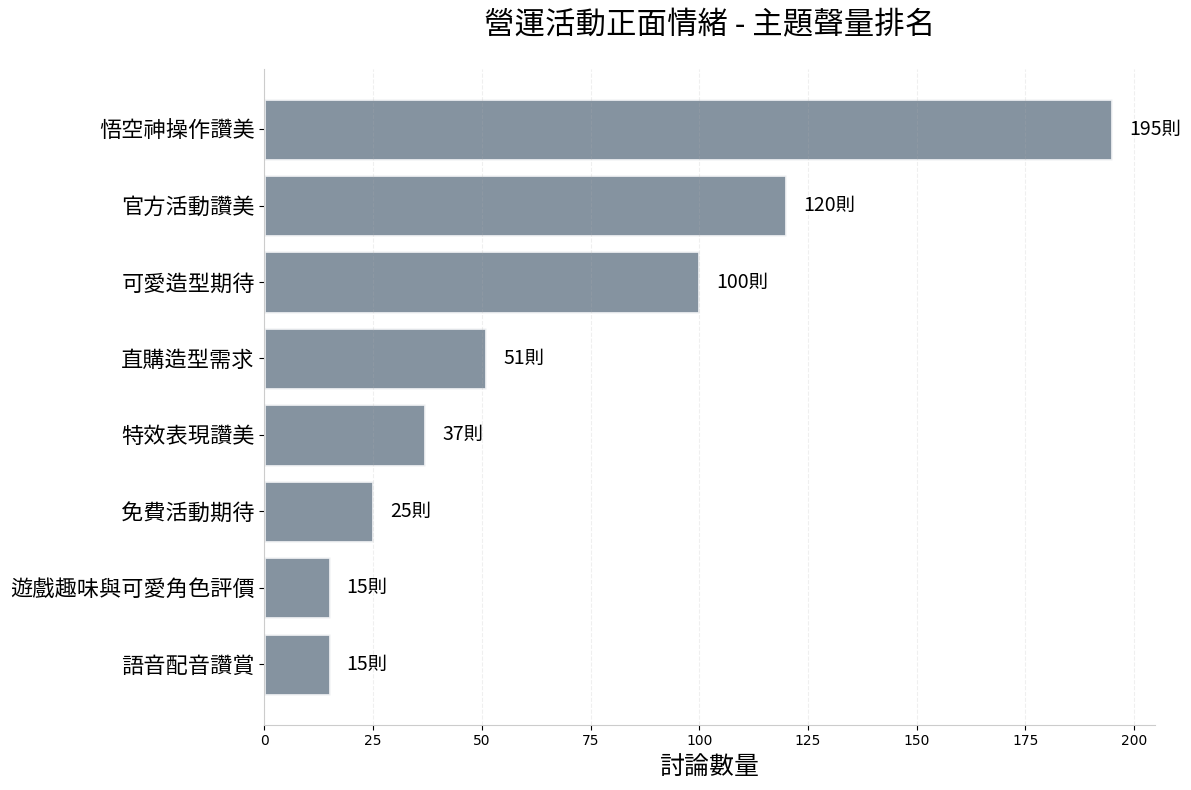

  生成 營運活動負面情緒 聲量排名...
主題排名圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/operation_negative_ranking.png


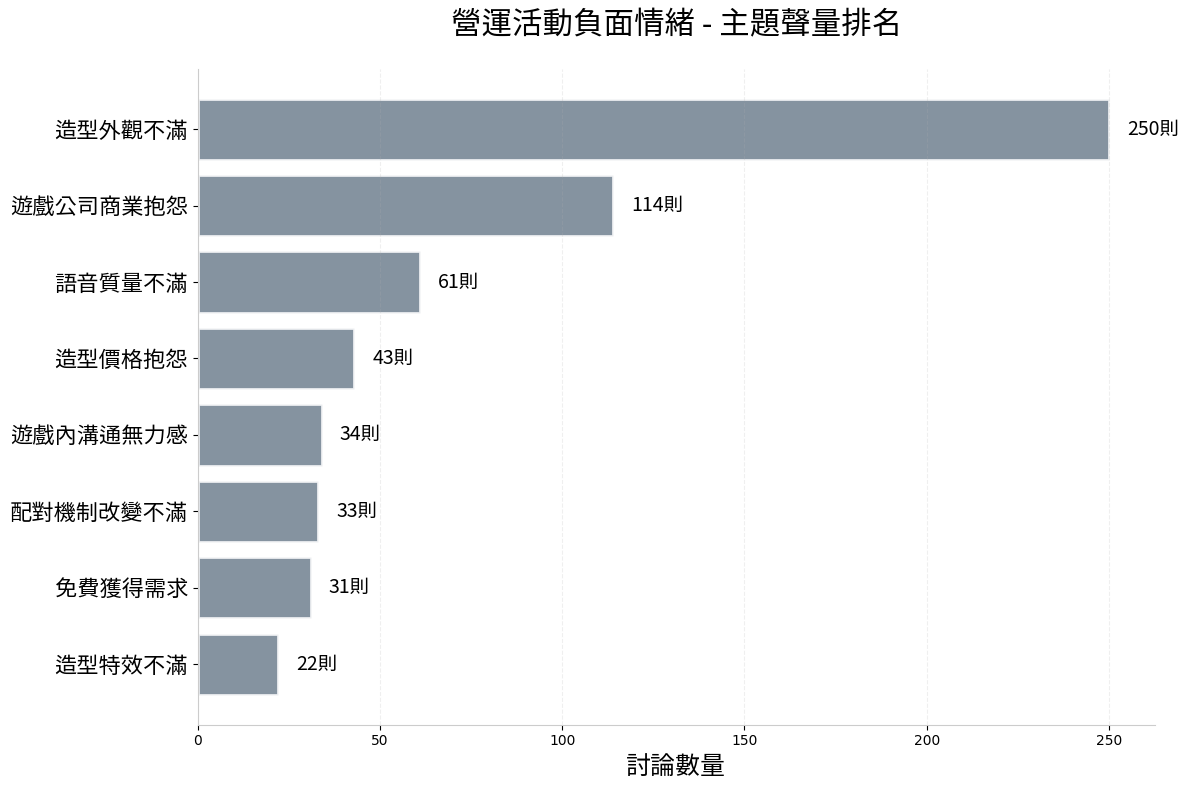

  生成 IP聯動正面情緒 聲量排名...
主題排名圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/ip_positive_ranking.png


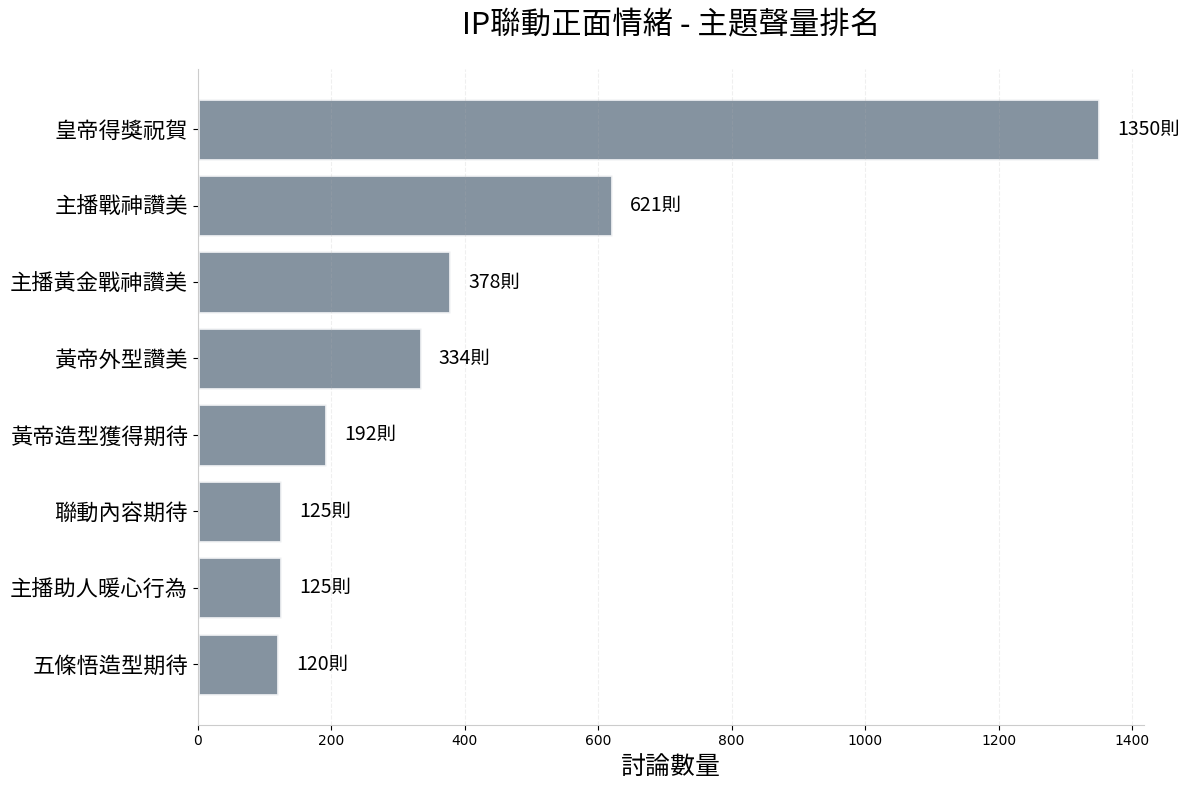

  生成 IP聯動負面情緒 聲量排名...
主題排名圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/ip_negative_ranking.png


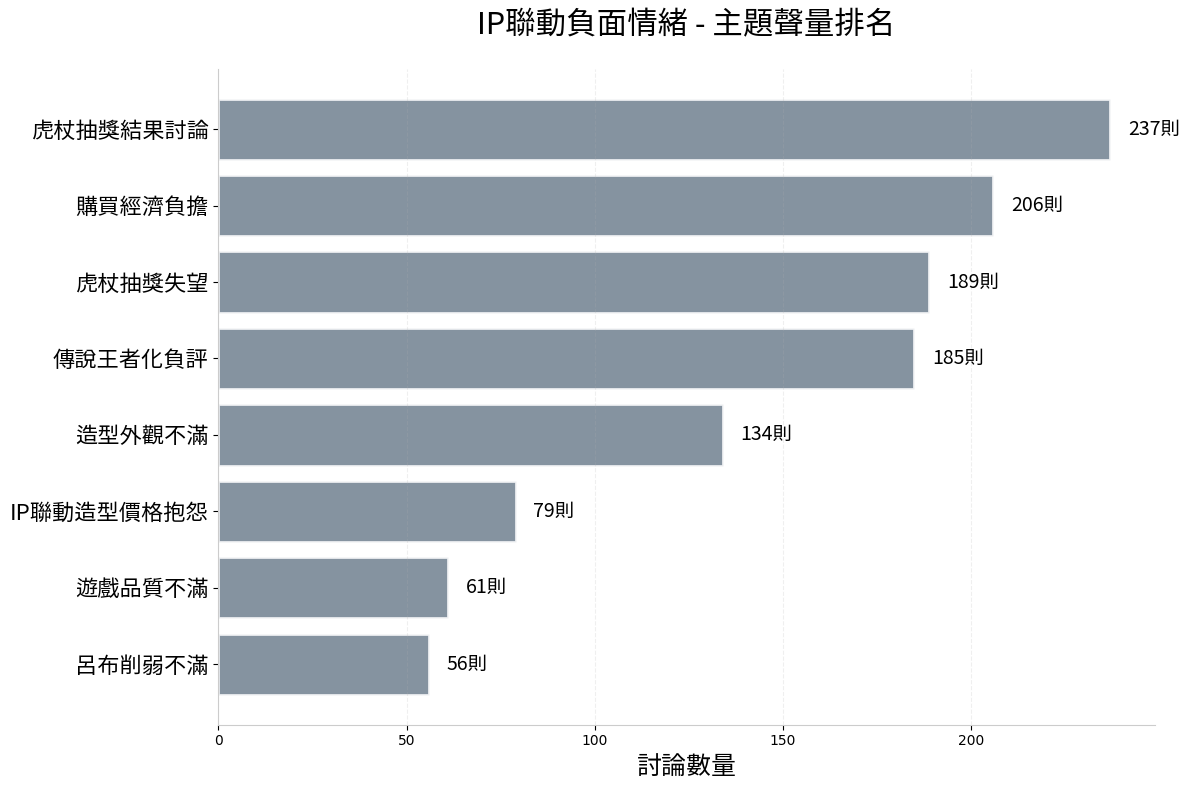

  生成 平衡性版本更新 聲量排名...
主題排名圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/balance_update_ranking.png


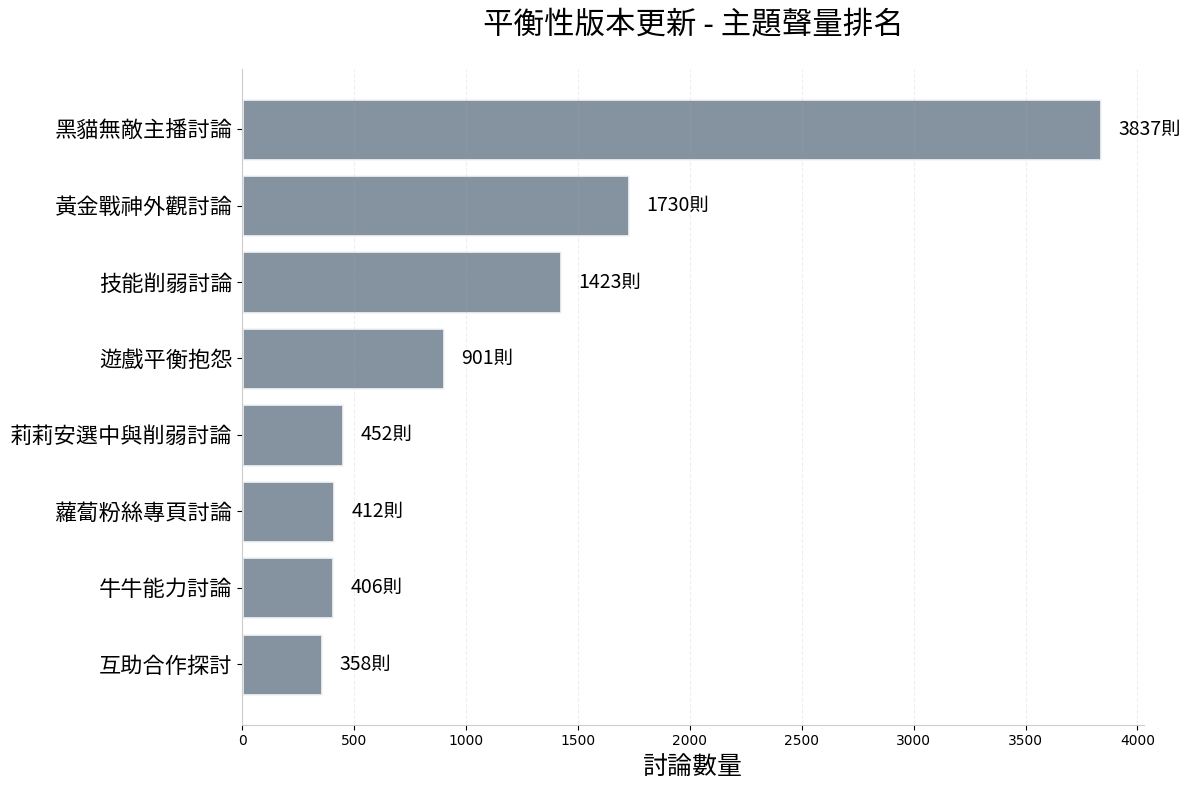

生成語意詞雲圖...
  生成 營運活動正面情緒 語意詞雲...
語意詞雲圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/operation_positive_semantic_wordcloud.png


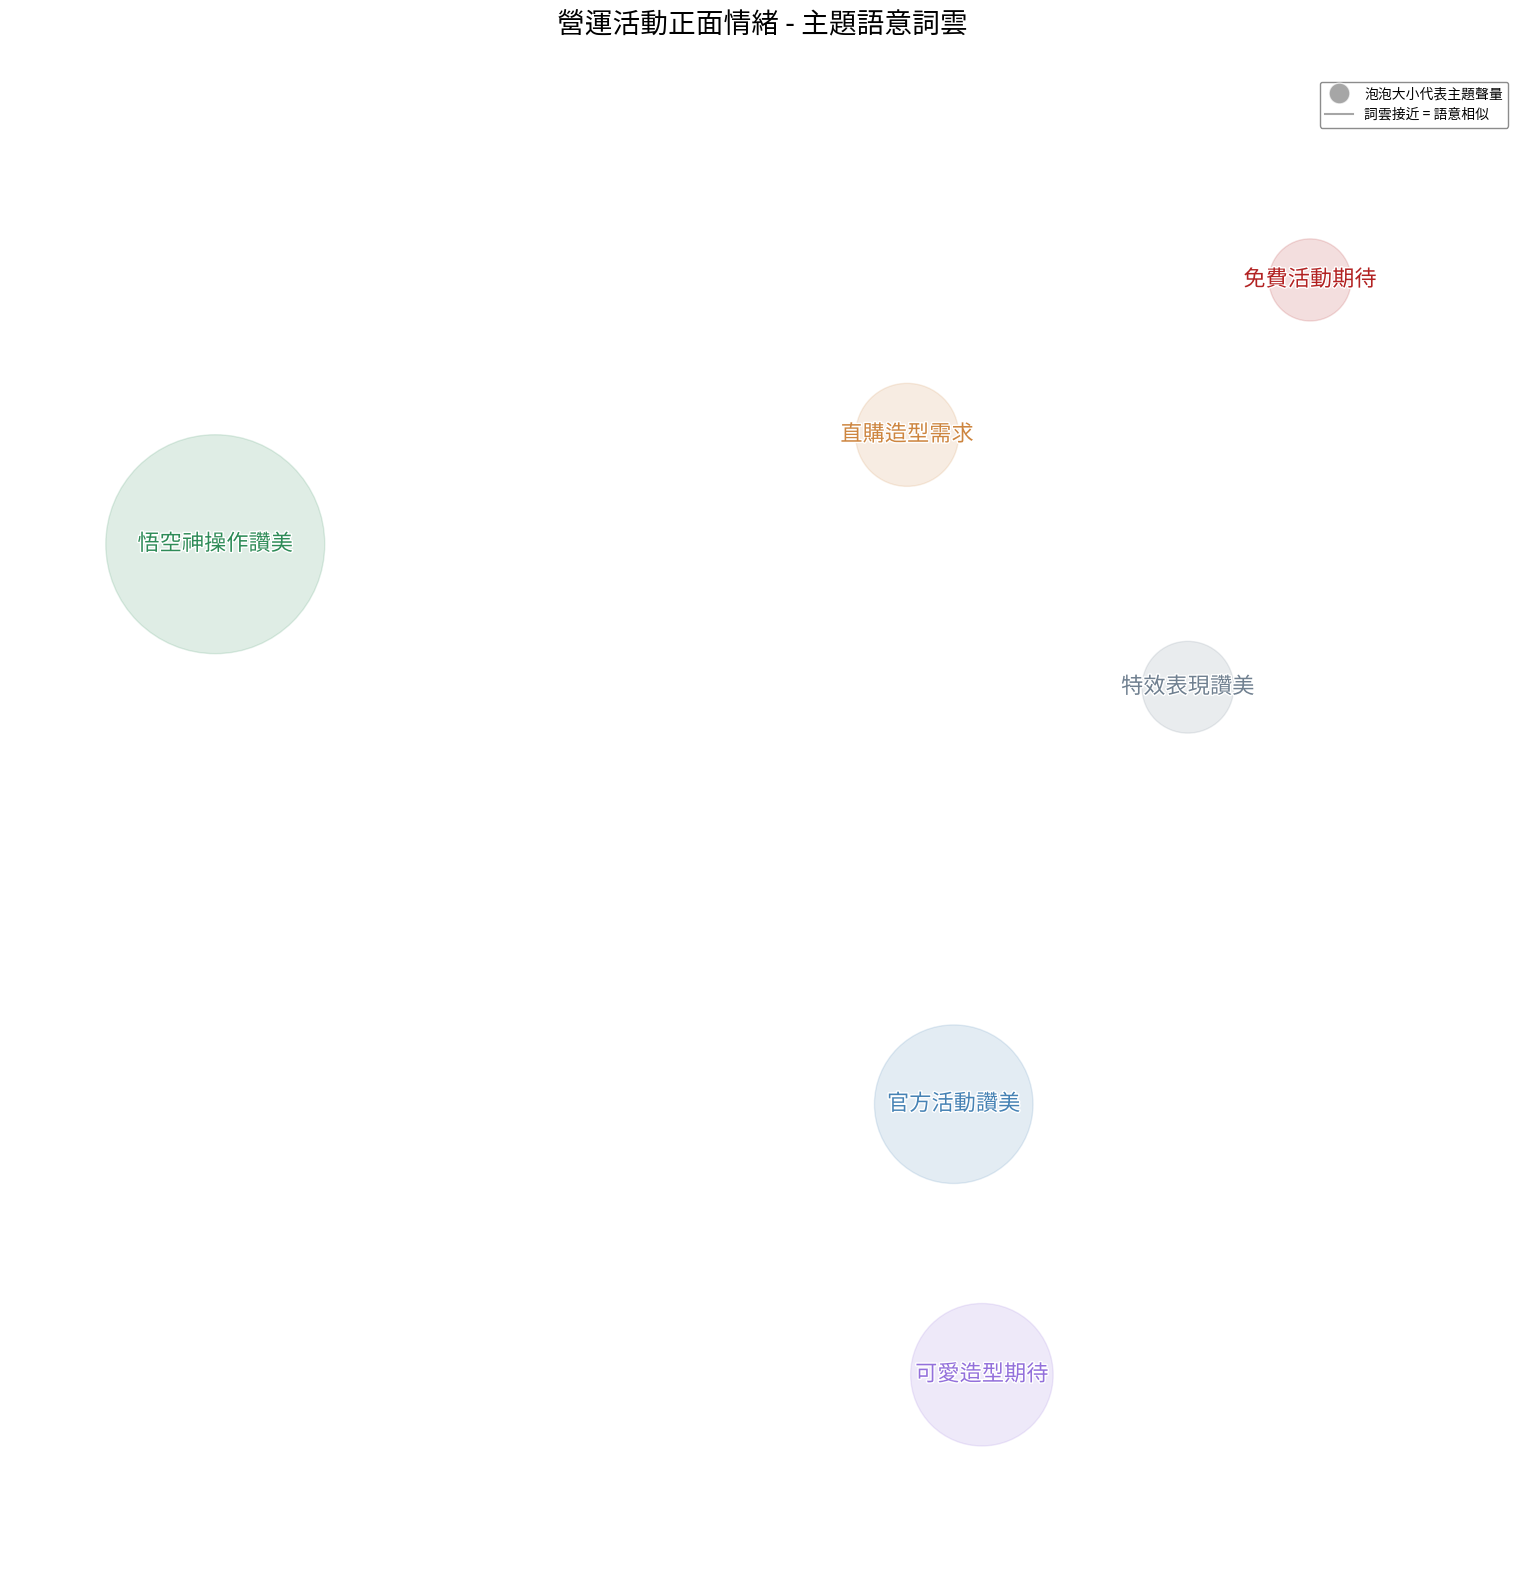

  生成 營運活動負面情緒 語意詞雲...
語意詞雲圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/operation_negative_semantic_wordcloud.png


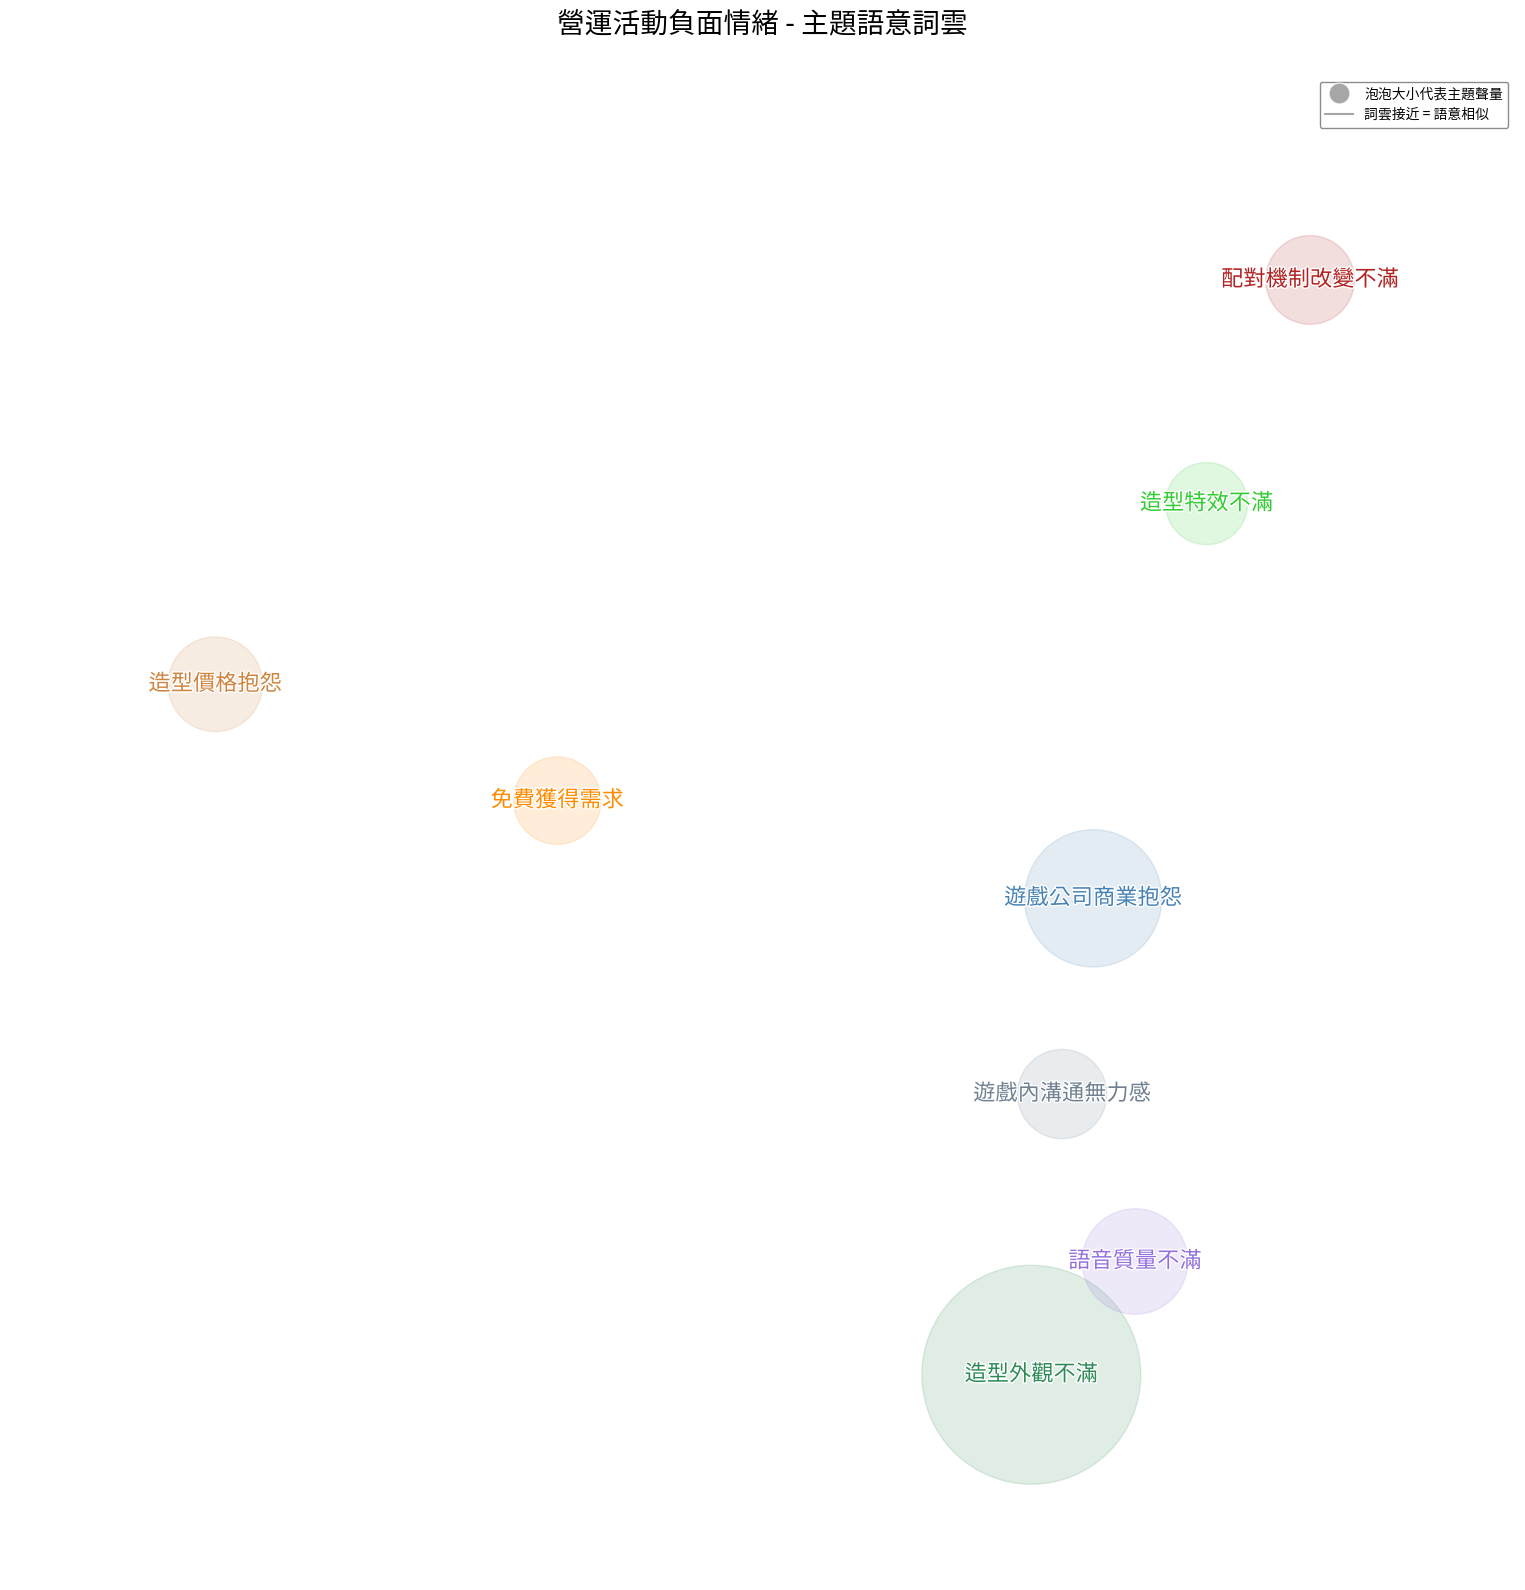

  生成 IP聯動正面情緒 語意詞雲...
語意詞雲圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/ip_positive_semantic_wordcloud.png


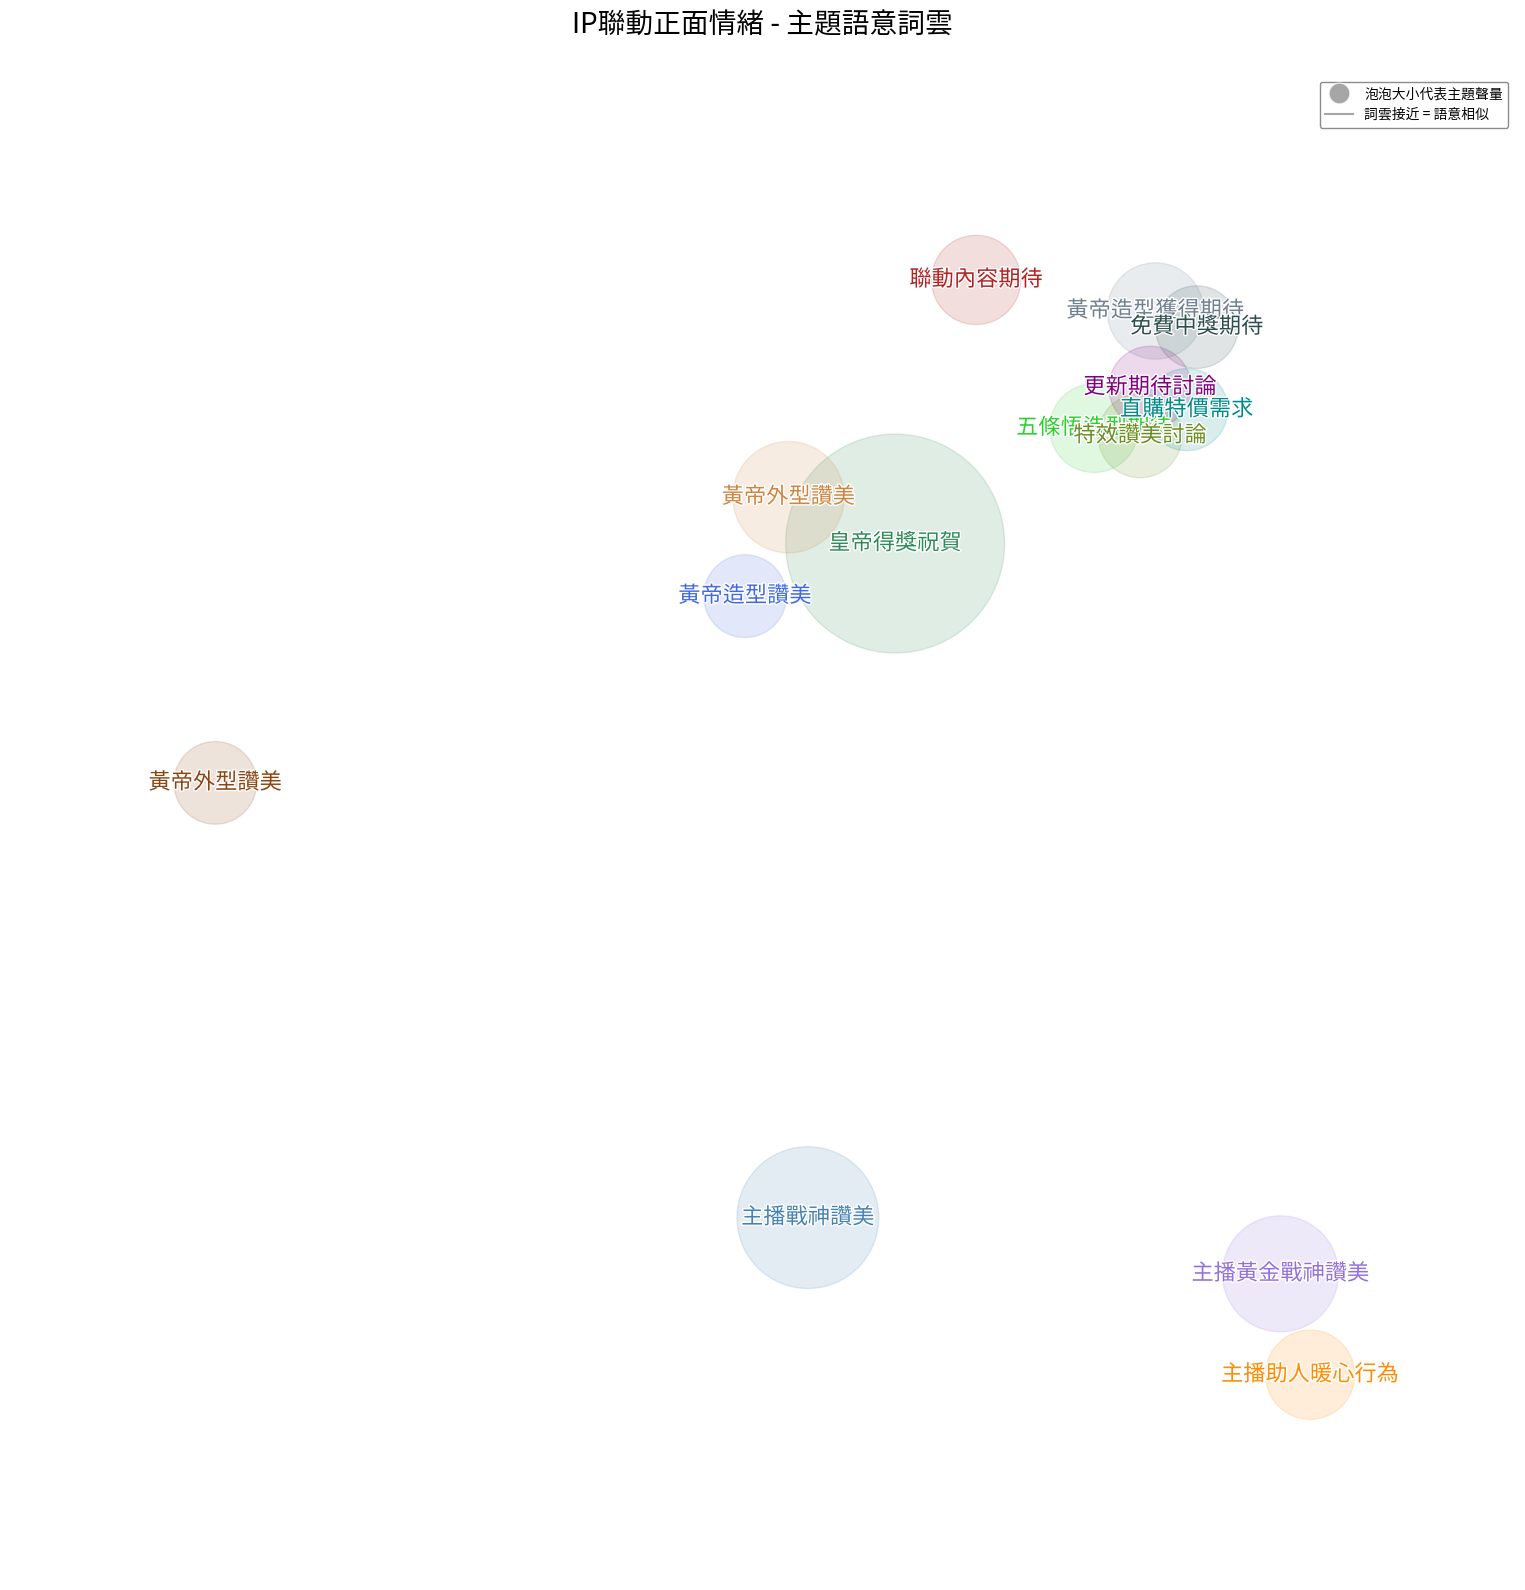

  生成 IP聯動負面情緒 語意詞雲...
語意詞雲圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/ip_negative_semantic_wordcloud.png


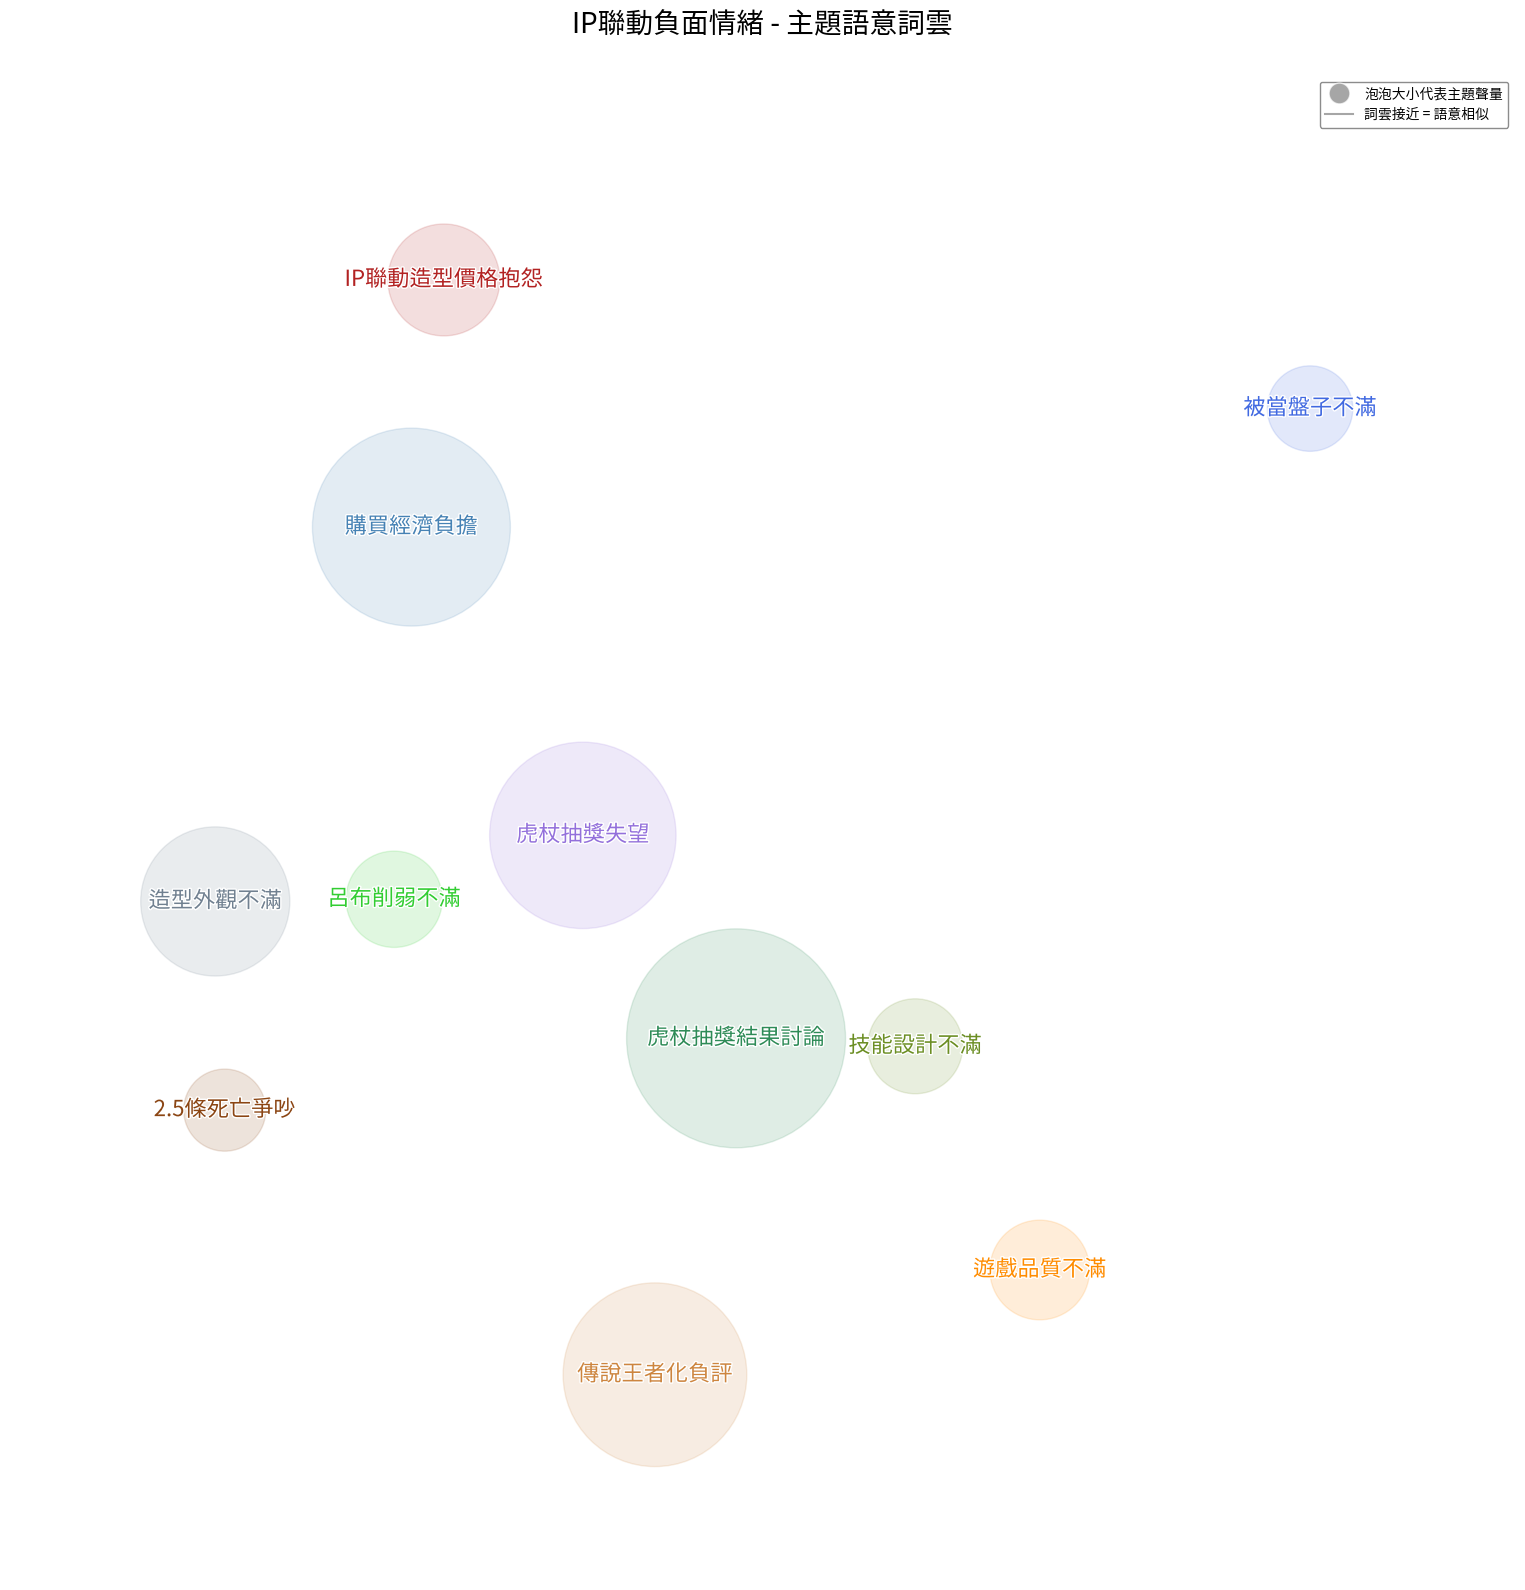

  生成 平衡性版本更新 語意詞雲...
語意詞雲圖已儲存: /content/drive/MyDrive/Garena_BERTopic_Project/results/balance_update_semantic_wordcloud.png


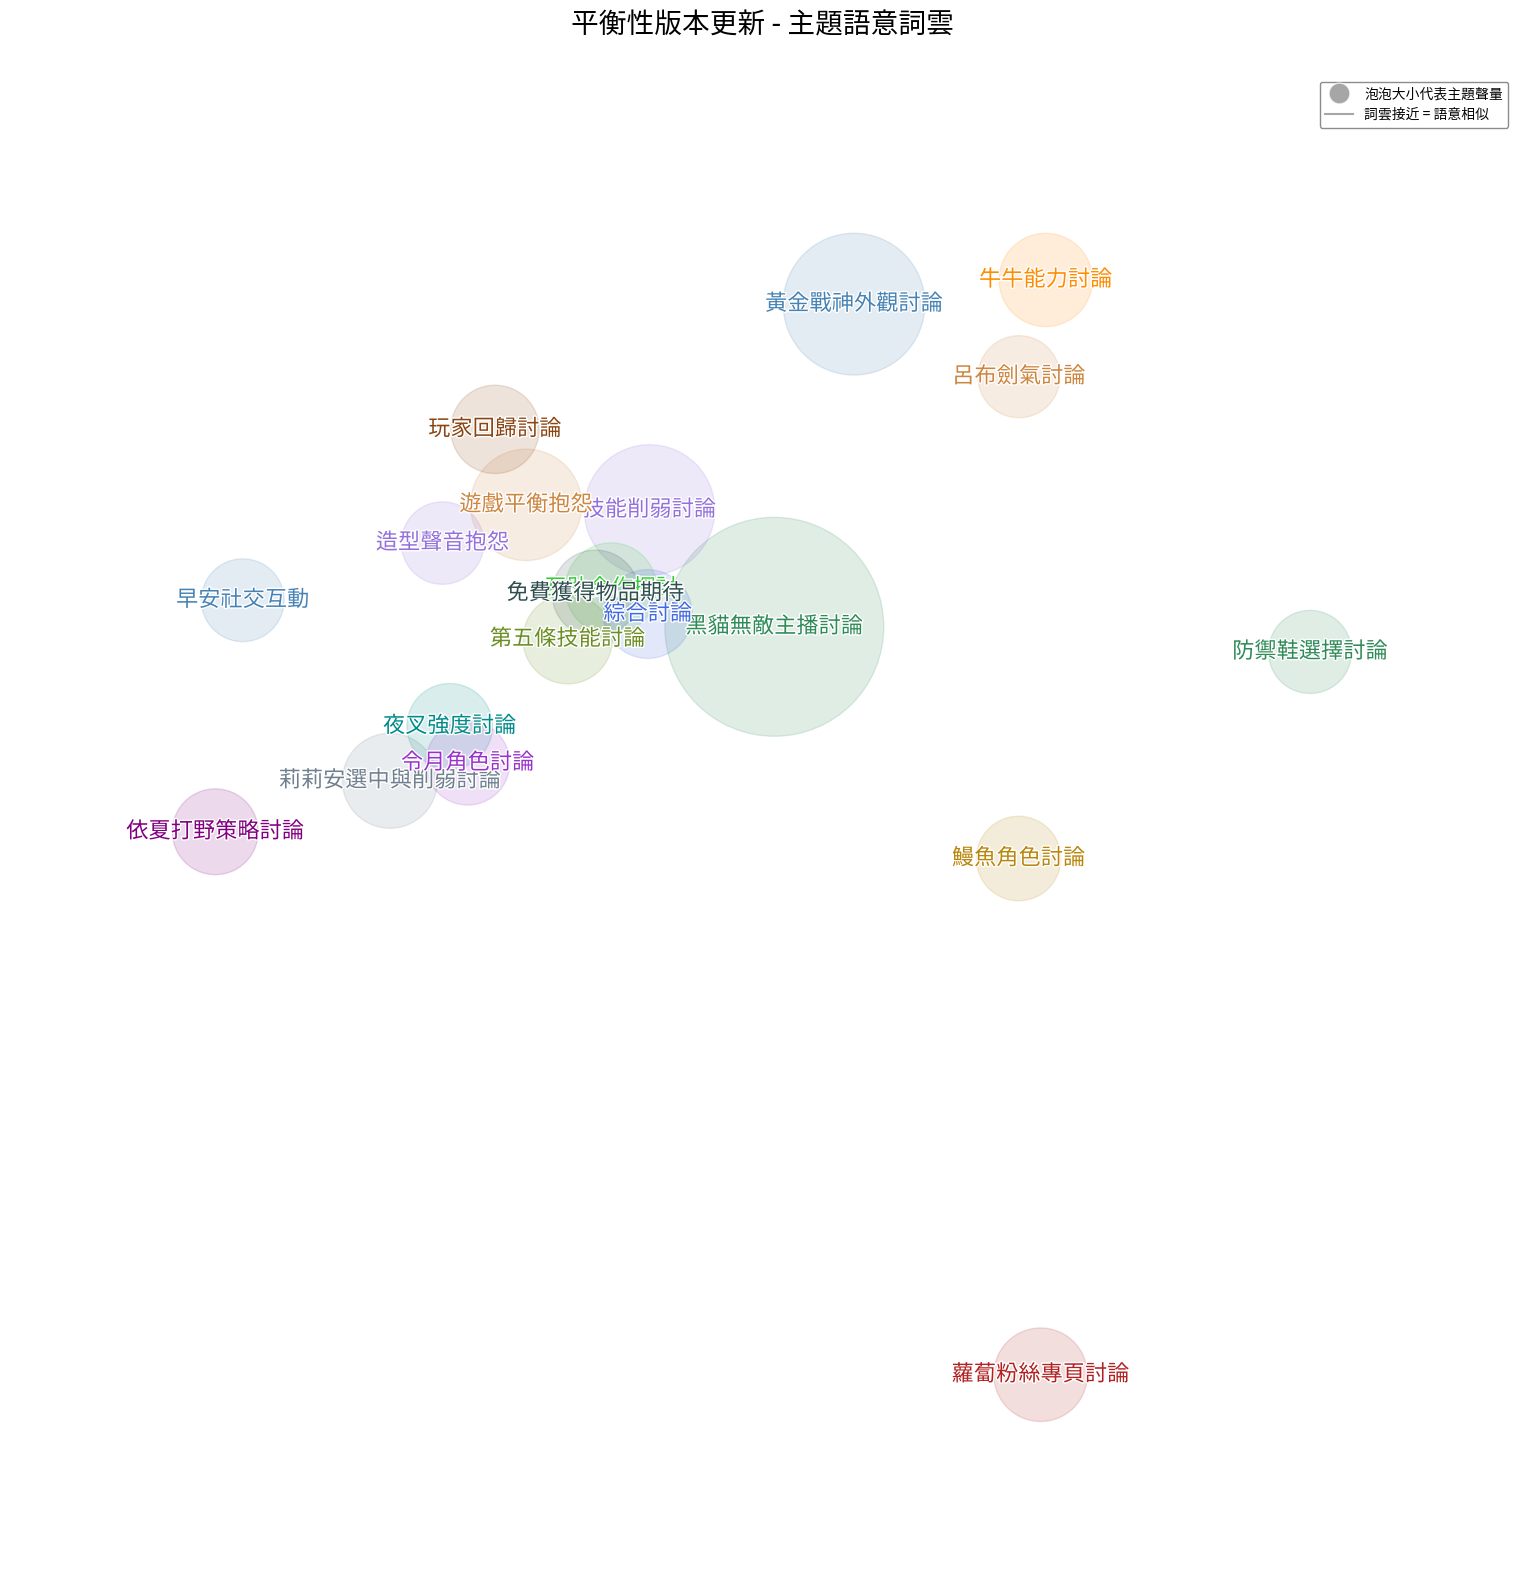


專業輿情視覺化完成，圖表已儲存至: /content/drive/MyDrive/Garena_BERTopic_Project/results

生成的圖表類型:
主題聲量排名圖: {dataset}_ranking.png
語意詞雲圖: {dataset}_semantic_wordcloud.png
總計10張專業圖表


In [ ]:
# 生成所有圖表
generate_all_visualizations()

# 生成特定資料集
# generate_single_dataset_visualization('operation_positive')